# Лабораторная работа №2. Классификация. Нейронные сети

## 1. Введение

**Цель работы** – изучение методов классификации данных, реализованных в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями на основе библиотеки TensorFlow (Keras) и средством визуализации процесса обучения TensorBoard.

**Задачи работы:**

1. Выбрать и подготовить набор данных для задачи классификации: провести разведочный анализ признаков, обработать выбросы и асимметричные распределения, выполнить стандартизацию.
2. Разделить данные на обучающую и тестовую выборки (функция `train_test_split`, соотношение 80/20, стратификация по классу, `random_state=42`).
3. Построить классификаторы пятью методами:
   1. наивный байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);
   2. дерево решений (Decision Tree);
   3. линейный дискриминантный анализ (Linear Discriminant Analysis, LDA);
   4. метод опорных векторов (Support Vector Machines, SVM);
   5. метод k ближайших соседей (k-Nearest Neighbors, kNN).
4. Сравнить качество классификаторов по метрикам Accuracy, Precision, Recall, F1-score и ROC-AUC.
5. Настроить гиперпараметры каждого метода (кросс-валидация, `GridSearchCV`, кривые валидации) и исследовать влияние параметров на качество классификации.
6. Построить нейронную сеть на TensorFlow, исследовать влияние числа эпох, размера батча, числа слоёв и нейронов, функций активации на качество модели и визуализировать процесс обучения в TensorBoard.
7. Провести сравнительный анализ и обосновать выбор наилучшего подхода для рассматриваемого набора данных.

Для воспроизводимости результатов все источники случайности зафиксированы значением `SEED = 42`: разбиение выборки, формирование фолдов кросс-валидации, построение деревьев, инициализация весов нейронной сети. Для TensorFlow дополнительно включён детерминированный режим вычислений (`enable_op_determinism`). Повторный запуск ноутбука воспроизводит все метрики без изменений.

## 2. Выбор и подготовка датасета

В работе используется набор данных [Wine Quality Dataset](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset) (файл `WineQT.csv`). Он является подмножеством известного набора UCI Wine Quality (P. Cortez и др., 2009) и содержит результаты физико-химического анализа образцов красного португальского вина «Vinho Verde» вместе с экспертной оценкой их качества. Каждый образец оценивался дегустаторами по шкале от 0 до 10; итоговая оценка – медиана не менее трёх экспертных оценок.

Набор содержит 1 143 образца, 11 числовых признаков, оценку качества и служебный столбец `Id` (номер строки в исходном наборе UCI), который в моделировании не используется.

**Постановка задачи.** Оценки в выборке принимают значения от 3 до 8, причём крайние оценки встречаются редко (оценку 3 имеют 6 образцов, оценку 8 – 16). Многоклассовая постановка с шестью сильно несбалансированными классами плохо подходит для сравнения бинарных метрик Precision, Recall и ROC-AUC, поэтому, как принято в работах по этому набору данных, задача сводится к бинарной классификации:

$$
y = \begin{cases} 1 \;(\text{«хорошее вино»}), & \text{оценка} \ge 6, \\ 0 \;(\text{«обычное вино»}), & \text{оценка} \le 5. \end{cases}
$$

Порог 6 делит выборку почти пополам и соответствует естественной границе «выше / ниже среднего» на шкале оценок. Положительным классом считается «хорошее вино».

Описание столбцов:

| Признак | Исходное имя | Содержание | Единицы |
|---|---|---|---|
| Фиксированная кислотность | `fixed acidity` | Нелетучие кислоты (в основном винная) | г винной кислоты / дм³ |
| Летучая кислотность | `volatile acidity` | Уксусная кислота; при высоком содержании придаёт вину неприятный уксусный привкус | г уксусной кислоты / дм³ |
| Лимонная кислота | `citric acid` | Придаёт «свежесть» вкусу | г / дм³ |
| Остаточный сахар | `residual sugar` | Сахар, оставшийся после брожения | г / дм³ |
| Хлориды | `chlorides` | Содержание соли | г хлорида натрия / дм³ |
| Свободный SO2 | `free sulfur dioxide` | Свободная форма диоксида серы; препятствует окислению и росту микроорганизмов | мг / дм³ |
| Общий SO2 | `total sulfur dioxide` | Свободная и связанная формы SO2 | мг / дм³ |
| Плотность | `density` | Плотность вина, зависит от содержания спирта и сахара | г / см³ |
| pH | `pH` | Кислотность по шкале pH | – |
| Сульфаты | `sulphates` | Добавка сульфата калия, источник SO2 (антимикробное и антиоксидантное действие) | г сульфата калия / дм³ |
| Алкоголь | `alcohol` | Содержание спирта | % об. |
| Оценка качества | `quality` | Экспертная оценка (3–8 в данной выборке); используется только для построения целевой переменной | баллы |
| Хорошее вино | – | Целевая переменная: 1 – оценка ≥ 6, 0 – оценка ≤ 5 | – |

In [1]:
%matplotlib inline
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # скрыть служебные сообщения TensorFlow
import time
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, validation_curve,
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["figure.dpi"] = 110

RU_NAMES = {
    "fixed acidity": "Фиксированная кислотность",
    "volatile acidity": "Летучая кислотность",
    "citric acid": "Лимонная кислота",
    "residual sugar": "Остаточный сахар",
    "chlorides": "Хлориды",
    "free sulfur dioxide": "Свободный SO2",
    "total sulfur dioxide": "Общий SO2",
    "density": "Плотность",
    "pH": "pH",
    "sulphates": "Сульфаты",
    "alcohol": "Алкоголь",
    "quality": "Оценка качества",
}
QUALITY = "Оценка качества"
TARGET = "Хорошее вино"

df_raw = pd.read_csv("data/WineQT.csv")
df = df_raw.drop(columns="Id").rename(columns=RU_NAMES)
df[TARGET] = (df[QUALITY] >= 6).astype(int)

print(f"Размерность исходного файла: {df_raw.shape[0]} образцов, {df_raw.shape[1]} столбцов "
      f"(11 признаков + оценка качества + Id)")
print("Первые 5 строк:")
display(df.head())
print("Пропущенные значения:")
display(df.isnull().sum().rename("Пропуски").to_frame().T)
print(f"Полных дубликатов строк (без учёта Id): {df.duplicated().sum()}")
print("Распределение экспертной оценки качества:")
display(pd.DataFrame({
    "Образцов": df[QUALITY].value_counts().sort_index(),
    "Доля, %": (df[QUALITY].value_counts(normalize=True).sort_index() * 100).round(2),
}).T)
print("Баланс классов бинарной целевой переменной (оценка ≥ 6):")
display(pd.DataFrame({
    "Образцов": df[TARGET].value_counts().sort_index(),
    "Доля, %": (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index={0: "0 – обычное (3–5)", 1: "1 – хорошее (6–8)"}))

Размерность исходного файла: 1143 образцов, 13 столбцов (11 признаков + оценка качества + Id)
Первые 5 строк:


,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный SO2,Общий SO2,Плотность,pH,Сульфаты,Алкоголь,Оценка качества,Хорошее вино
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


Пропущенные значения:


,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный SO2,Общий SO2,Плотность,pH,Сульфаты,Алкоголь,Оценка качества,Хорошее вино
Пропуски,0,0,0,0,0,0,0,0,0,0,0,0,0


Полных дубликатов строк (без учёта Id): 125
Распределение экспертной оценки качества:


Оценка качества,3,4,5,6,7,8
Образцов,6.00,33.00,483.00,462.00,143.00,16.0
"Доля, %",0.52,2.89,42.26,40.42,12.51,1.4


Баланс классов бинарной целевой переменной (оценка ≥ 6):


,Образцов,"Доля, %"
Хорошее вино,,
0 – обычное (3–5),522,45.67
1 – хорошее (6–8),621,54.33


### Пояснение к загрузке данных

- Объём выборки: 1 143 образца вина, 11 физико-химических признаков, экспертная оценка качества и служебный столбец `Id`, который удалён (это номер строки исходного набора, а не свойство вина).
- Пропущенных значений нет ни в одном столбце, поэтому заполнение пропусков не требуется.
- Дубликаты: 125 строк (10.9%) полностью совпадают с другими строками по всем признакам и оценке. В исходном наборе UCI повторы возникли из-за того, что разные партии вина имели одинаковые результаты анализа. Дубликаты удаляются до разбиения выборки, иначе одна и та же запись может попасть и в обучающую, и в тестовую выборку, и оценка качества окажется завышенной.
- Распределение оценок сильно неравномерно: 82.7% образцов имеют оценку 5 или 6, крайние оценки 3 и 8 встречаются всего 6 и 16 раз. Обучить модель различать шесть таких классов на 1 143 объектах затруднительно, что подтверждает выбор бинарной постановки.
- Баланс классов после бинаризации: 621 хорошее вино (54.3%) и 522 обычных (45.7%). Классы близки к сбалансированным, поэтому специальные методы борьбы с дисбалансом не нужны, а тривиальный классификатор, всегда отвечающий «хорошее», имеет Accuracy около 0.54 – это нижняя граница для сравнения моделей.

In [2]:
feature_names = [c for c in df.columns if c not in (TARGET, QUALITY)]

stats_df = df[feature_names].describe().T
stats_df["Медиана"] = df[feature_names].median()
stats_df["Коэффициент асимметрии"] = df[feature_names].skew()
stats_df = stats_df.rename(columns={"mean": "Среднее", "std": "Станд. откл.", "min": "Минимум", "max": "Максимум",
                                    "25%": "Q1", "75%": "Q3"})
print("ОПИСАТЕЛЬНАЯ СТАТИСТИКА")
display(stats_df[["Среднее", "Станд. откл.", "Медиана", "Q1", "Q3", "Минимум", "Максимум",
                  "Коэффициент асимметрии"]].round(3))

q1, q3 = df[feature_names].quantile(0.25), df[feature_names].quantile(0.75)
iqr = q3 - q1
out_mask = (df[feature_names] < q1 - 1.5 * iqr) | (df[feature_names] > q3 + 1.5 * iqr)
far_mask = (df[feature_names] < q1 - 3 * iqr) | (df[feature_names] > q3 + 3 * iqr)
print("Выбросы по правилу межквартильного размаха (IQR):")
display(pd.DataFrame({
    "Выбросов (1.5·IQR)": out_mask.sum(),
    "Доля, %": out_mask.mean() * 100,
    "Экстремальных (3·IQR)": far_mask.sum(),
    "Доля хороших вин среди выбросов, %": [df.loc[out_mask[c], TARGET].mean() * 100 for c in feature_names],
}).sort_values("Выбросов (1.5·IQR)", ascending=False).round(1))
print(f"Строк хотя бы с одним выбросом: {out_mask.any(axis=1).sum()} из {len(df)}")

ОПИСАТЕЛЬНАЯ СТАТИСТИКА


,Среднее,Станд. откл.,Медиана,Q1,Q3,Минимум,Максимум,Коэффициент асимметрии
Фиксированная кислотность,8.311,1.748,7.900,7.100,9.100,4.600,15.900,1.045
Летучая кислотность,0.531,0.180,0.520,0.392,0.640,0.120,1.580,0.682
Лимонная кислота,0.268,0.197,0.250,0.090,0.420,0.000,1.000,0.372
Остаточный сахар,2.532,1.356,2.200,1.900,2.600,0.900,15.500,4.361
Хлориды,0.087,0.047,0.079,0.070,0.090,0.012,0.611,6.026
Свободный SO2,15.615,10.250,13.000,7.000,21.000,1.000,68.000,1.231
Общий SO2,45.915,32.782,37.000,21.000,61.000,6.000,289.000,1.666
Плотность,0.997,0.002,0.997,0.996,0.998,0.990,1.004,0.102
pH,3.311,0.157,3.310,3.205,3.400,2.740,4.010,0.221
Сульфаты,0.658,0.170,0.620,0.550,0.730,0.330,2.000,2.497


Выбросы по правилу межквартильного размаха (IQR):


,Выбросов (1.5·IQR),"Доля, %",Экстремальных (3·IQR),"Доля хороших вин среди выбросов, %"
Остаточный сахар,110,9.6,67,54.5
Хлориды,77,6.7,44,50.6
Фиксированная кислотность,44,3.8,4,63.6
Сульфаты,43,3.8,11,46.5
Общий SO2,40,3.5,2,17.5
Плотность,36,3.1,0,77.8
pH,20,1.7,2,60.0
Свободный SO2,18,1.6,3,33.3
Летучая кислотность,14,1.2,1,14.3
Алкоголь,12,1.0,0,91.7


Строк хотя бы с одним выбросом: 295 из 1143


### Пояснение к описательной статистике

- Признаки измерены в разных единицах и различаются по масштабу на пять порядков: плотность меняется в диапазоне 0.990–1.004 (стандартное отклонение 0.002), а общий SO2 – от 6 до 289 мг/дм³ (стандартное отклонение 32.8). Для методов, основанных на расстояниях (kNN, SVM) и градиентном обучении (нейронная сеть), стандартизация признаков обязательна.
- Сильная правосторонняя асимметрия: хлориды (коэффициент асимметрии 6.03, медиана 0.079, максимум 0.611 – в 7.7 раза больше медианы), остаточный сахар (4.36; медиана 2.2, максимум 15.5 г/дм³), сульфаты (2.50), общий SO2 (1.67). Длинные хвосты нарушают предположение о нормальности, на котором основаны GaussianNB и LDA, поэтому такие признаки целесообразно логарифмировать.
- Почти симметричны плотность (0.10), pH (0.22) и лимонная кислота (0.37).
- Выбросы по правилу 1.5·IQR есть в 295 строках из 1 143 (25.8%), больше всего их у остаточного сахара (110 строк) и хлоридов (77). Удалять такие строки нельзя: пришлось бы потерять четверть выборки. Кроме того, выбросы информативны: среди образцов с аномально высоким содержанием алкоголя 91.7% хороших вин, а среди образцов с аномально высокой летучей кислотностью или общим SO2 – только 14.3% и 17.5%. Поэтому выбросы не удаляются, а ограничиваются (винзоризация) и сглаживаются логарифмированием.

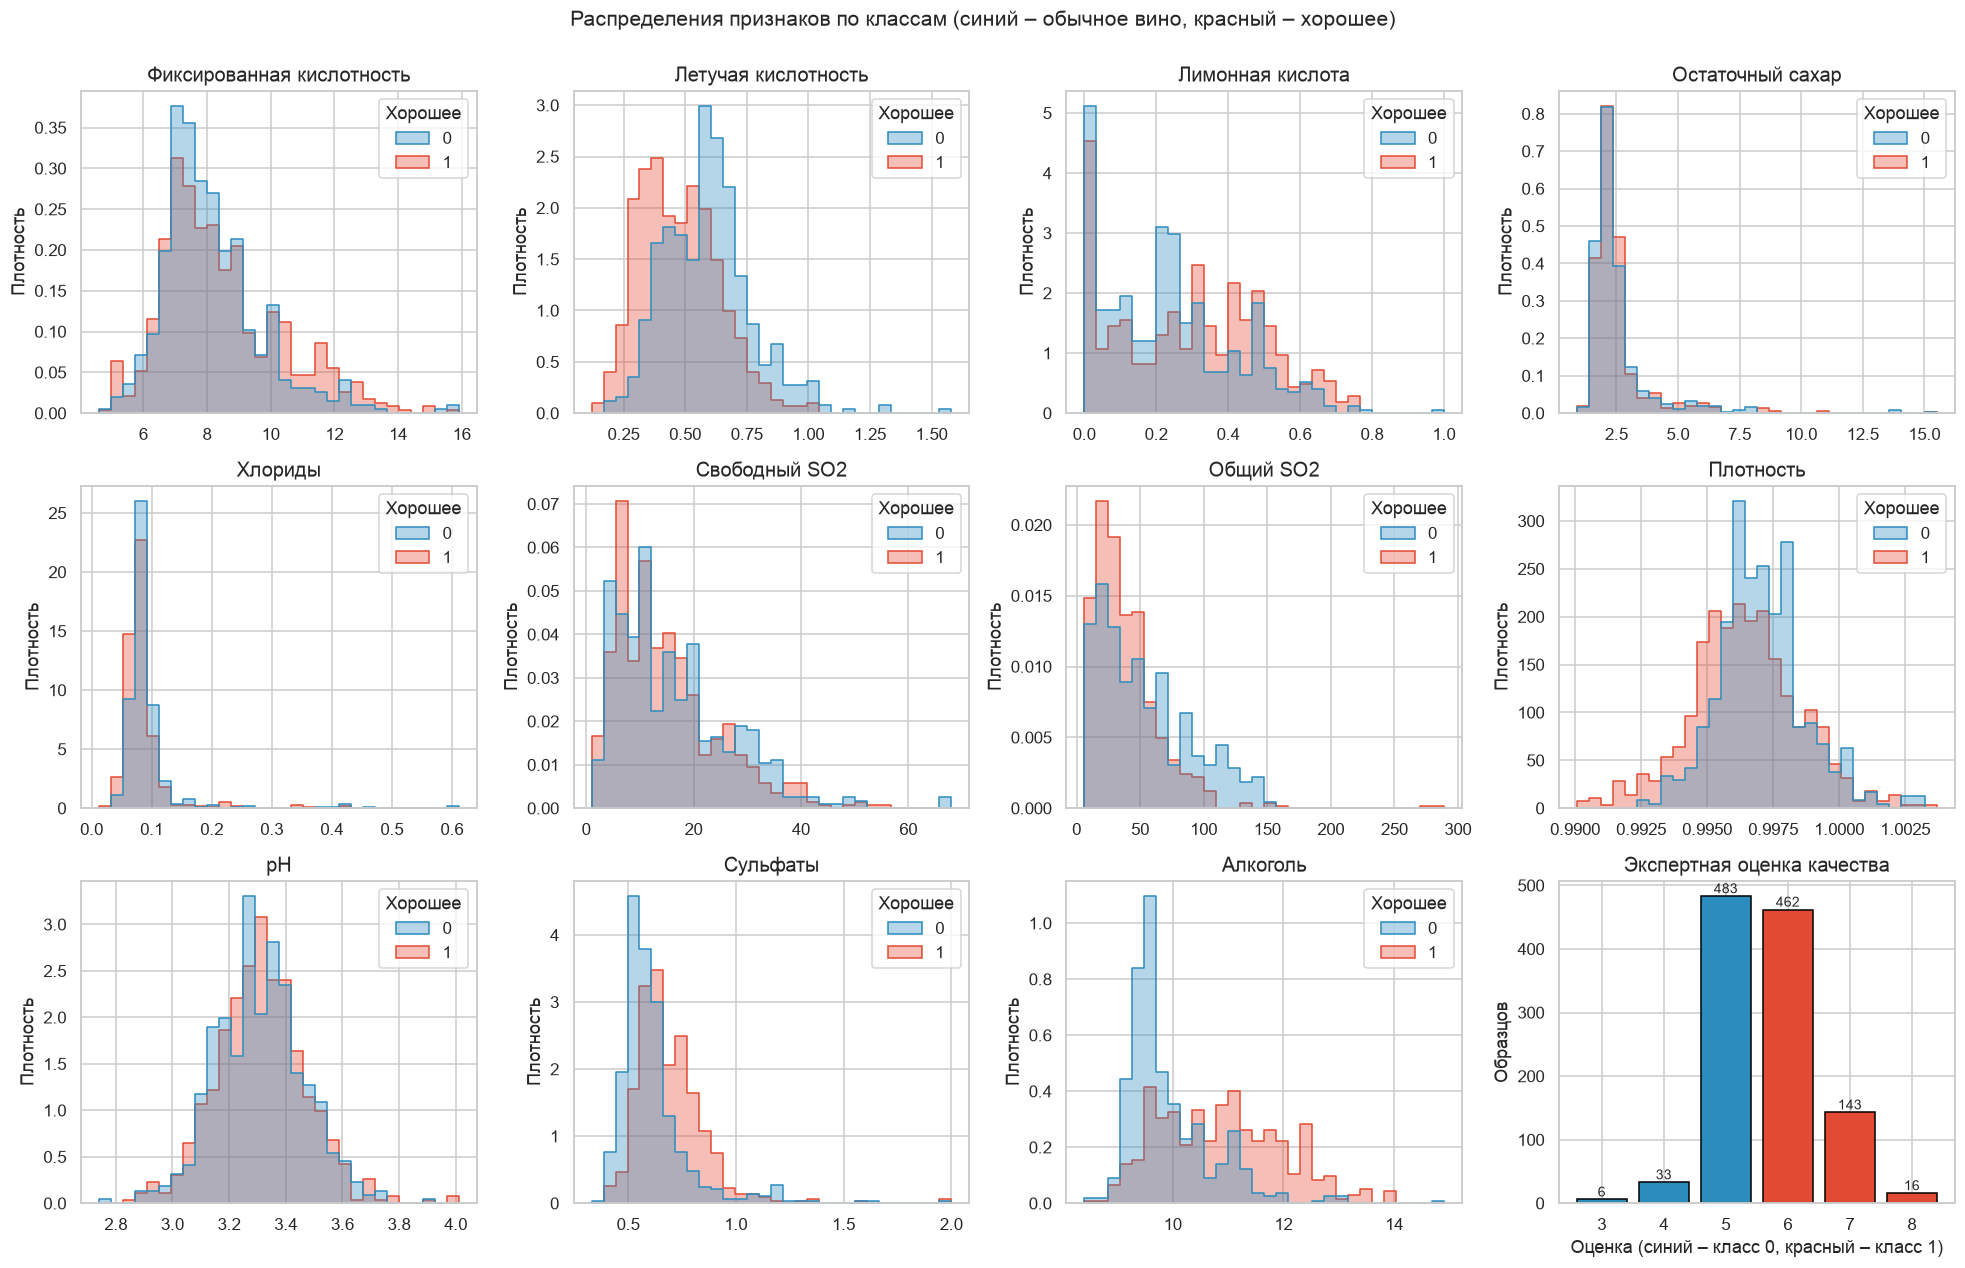

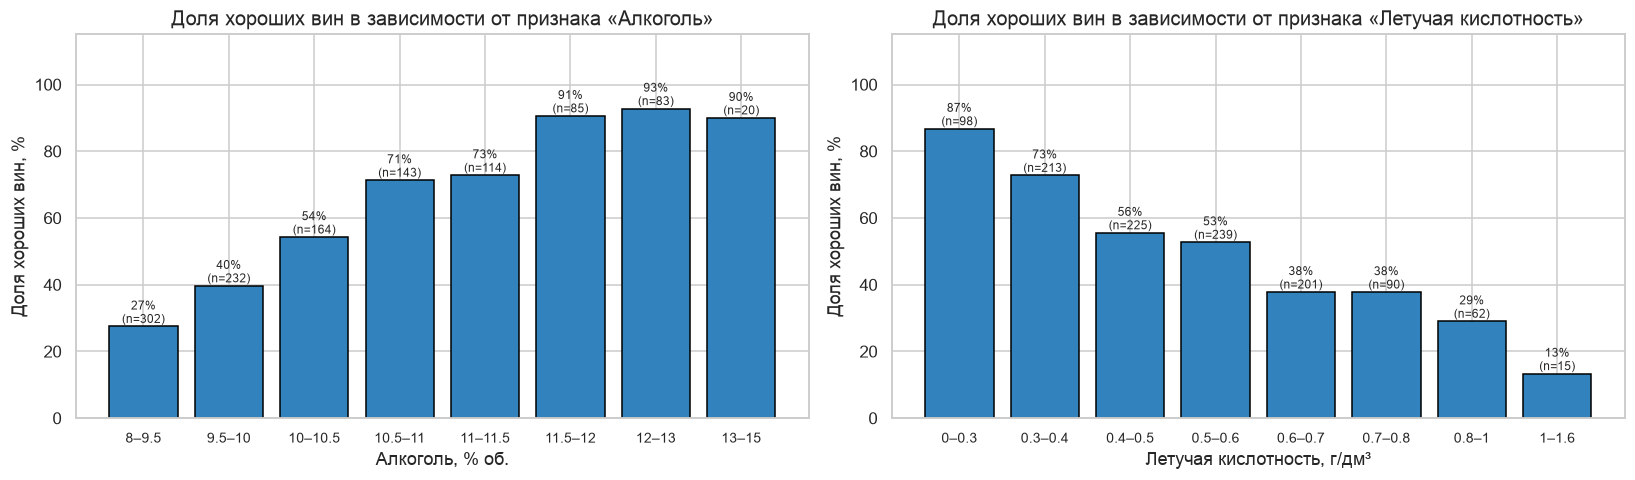

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11.5))
colors = {0: "#2b8cbe", 1: "#e34a33"}
for ax, col in zip(axes.ravel(), feature_names):
    sns.histplot(data=df, x=col, hue=TARGET, ax=ax, bins=30, stat="density", common_norm=False,
                 element="step", palette=colors, alpha=0.35)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Плотность")
    leg = ax.get_legend()
    if leg is not None:
        leg.set_title("Хорошее")
ax = axes.ravel()[-1]
cnt = df[QUALITY].value_counts().sort_index()
bars = ax.bar(cnt.index.astype(str), cnt.values, color=["#2b8cbe" if q < 6 else "#e34a33" for q in cnt.index],
              edgecolor="black")
ax.bar_label(bars, fontsize=9)
ax.set_title("Экспертная оценка качества")
ax.set_xlabel("Оценка (синий – класс 0, красный – класс 1)")
ax.set_ylabel("Образцов")
plt.suptitle("Распределения признаков по классам (синий – обычное вино, красный – хорошее)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (col, edges) in zip(axes, [
    ("Алкоголь", [8, 9.5, 10, 10.5, 11, 11.5, 12, 13, 15]),
    ("Летучая кислотность", [0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.6]),
]):
    bins = pd.cut(df[col], edges)
    rate = df.groupby(bins, observed=True)[TARGET].agg(["mean", "count"])
    bars = ax.bar([f"{iv.left:g}–{iv.right:g}" for iv in rate.index], rate["mean"] * 100,
                  color="#3182bd", edgecolor="black")
    ax.bar_label(bars, labels=[f"{m*100:.0f}%\n(n={n})" for m, n in zip(rate["mean"], rate["count"])], fontsize=8)
    ax.set_ylim(0, 115)
    ax.set_xlabel(col + (", % об." if col == "Алкоголь" else ", г/дм³"))
    ax.set_ylabel("Доля хороших вин, %")
    ax.set_title(f"Доля хороших вин в зависимости от признака «{col}»")
    ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
plt.show()

### Пояснение к графикам распределения

Гистограммы построены отдельно для каждого класса и нормированы на его объём, что позволяет сравнивать форму распределений.

- Наиболее заметно классы различаются по содержанию алкоголя: у обычных вин распределение сосредоточено в узком пике 9–10% об., у хороших оно смещено вправо и растянуто до 13–14%. Столбчатая диаграмма показывает монотонную зависимость: при содержании алкоголя ниже 9.5% хороших вин лишь 27%, в диапазоне 10–10.5% – 54%, а при содержании выше 11.5% – более 90%.
- Летучая кислотность действует в противоположном направлении: при значениях до 0.3 г/дм³ доля хороших вин составляет 87%, при 0.6–0.8 г/дм³ – 38%, а при значениях свыше 1 г/дм³ – 13% (высокое содержание уксусной кислоты воспринимается дегустаторами как порок вина).
- Сульфаты у хороших вин в среднем выше (распределение смещено вправо), общий SO2 и плотность – немного ниже.
- Распределения pH, остаточного сахара, хлоридов и свободного SO2 у двух классов практически совпадают, поэтому по отдельности эти признаки слабо информативны.
- Ни один признак не разделяет классы полностью: распределения существенно перекрываются. Это означает, что от моделей не следует ожидать очень высокой точности; кроме того, экспертная оценка субъективна, а граница между оценками 5 и 6 размыта.

Связь признаков с целевыми переменными:


,Пирсон (класс),Спирмен (класс),Спирмен (оценка 3–8)
Летучая кислотность,-0.331,-0.336,-0.398
Общий SO2,-0.227,-0.195,-0.195
Хлориды,-0.101,-0.173,-0.194
Плотность,-0.154,-0.158,-0.177
Свободный SO2,-0.071,-0.054,-0.059
Остаточный сахар,-0.008,0.012,0.031
pH,0.015,0.013,-0.033
Фиксированная кислотность,0.089,0.070,0.104
Лимонная кислота,0.155,0.155,0.223
Сульфаты,0.234,0.358,0.394


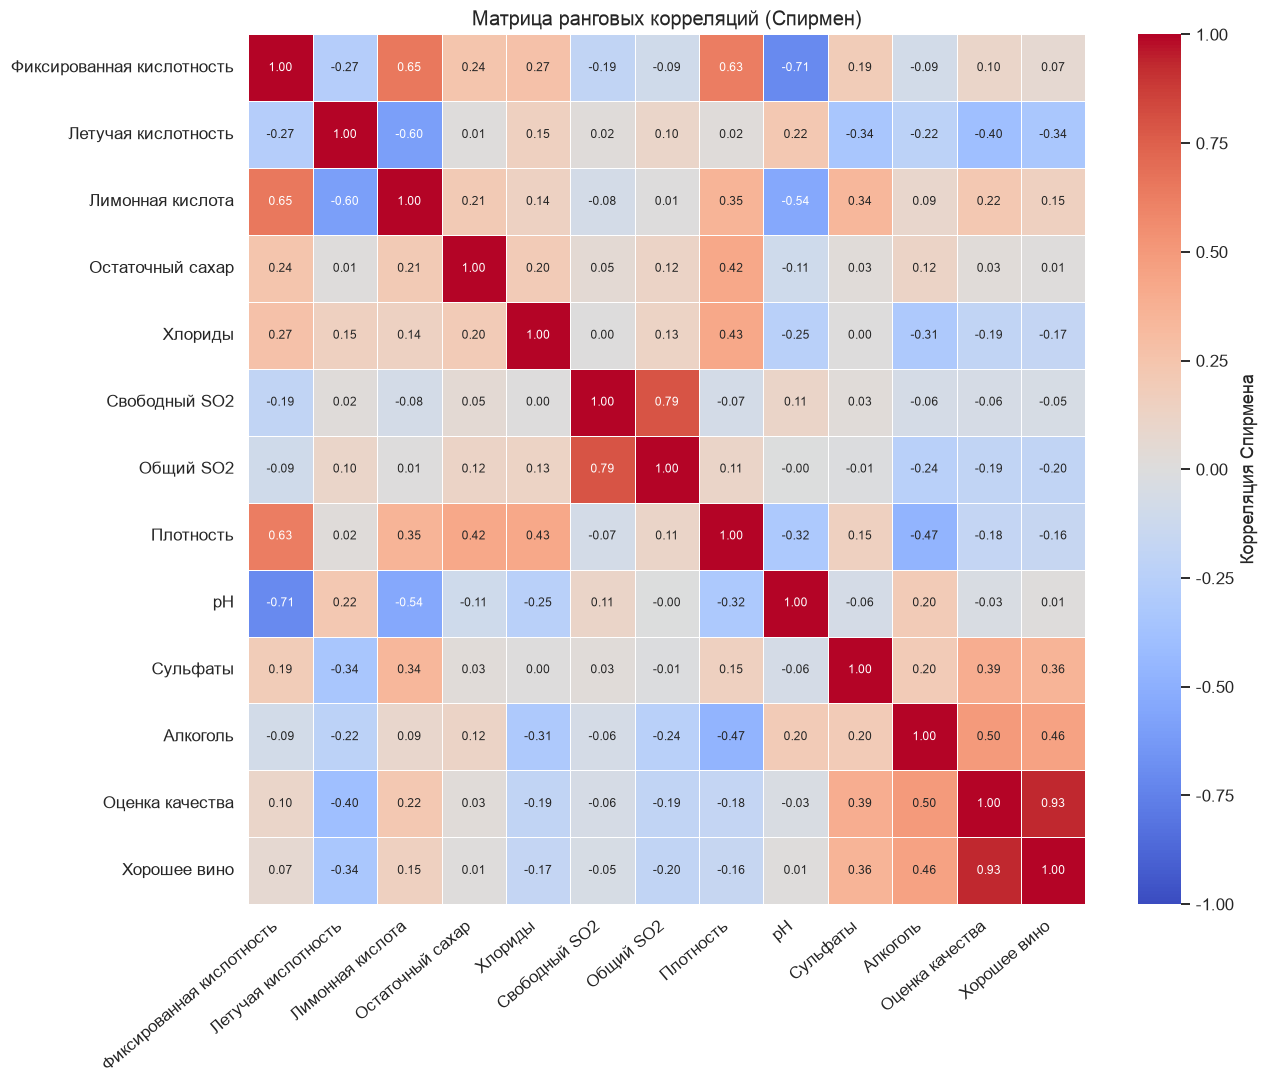

In [4]:
corr_cols = feature_names + [QUALITY, TARGET]
corr_p = df[corr_cols].corr(method="pearson")
corr_s = df[corr_cols].corr(method="spearman")
print("Связь признаков с целевыми переменными:")
display(pd.DataFrame({
    "Пирсон (класс)": corr_p[TARGET].drop([TARGET, QUALITY]),
    "Спирмен (класс)": corr_s[TARGET].drop([TARGET, QUALITY]),
    "Спирмен (оценка 3–8)": corr_s[QUALITY].drop([TARGET, QUALITY]),
}).sort_values("Спирмен (класс)").round(3))

plt.figure(figsize=(12, 10))
sns.heatmap(corr_s, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.4, annot_kws={"size": 8}, cbar_kws={"label": "Корреляция Спирмена"})
plt.title("Матрица ранговых корреляций (Спирмен)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

### Пояснение к корреляциям

Используется ранговая корреляция Спирмена: она устойчива к выбросам и улавливает любые монотонные зависимости, а не только линейные.

- Наиболее сильно с классом связаны алкоголь (+0.458), сульфаты (+0.358) и летучая кислотность (−0.336); заметно слабее – общий SO2 (−0.195), хлориды (−0.173), плотность (−0.158) и лимонная кислота (+0.155). Связь остаточного сахара (+0.012), pH (+0.013) и свободного SO2 (−0.054) с классом близка к нулю.
- Для сульфатов коэффициент Пирсона (+0.234) заметно ниже коэффициента Спирмена (+0.358): единичные очень большие значения (до 2.0 г/дм³) ослабляют линейную корреляцию, хотя монотонная связь выражена. Это дополнительный довод в пользу логарифмирования этого признака.
- Корреляции с исходной шкалой оценок (3–8) по модулю немного выше, чем с бинарным классом, поскольку при бинаризации теряется часть информации. Порядок признаков по силе связи при этом сохраняется.
- Между признаками есть сильные корреляции: фиксированная кислотность связана с pH (−0.71), лимонной кислотой (+0.65) и плотностью (+0.63); свободный и общий SO2 (+0.79); летучая кислотность и лимонная кислота (−0.60); плотность и алкоголь (−0.47). Мультиколлинеарность нарушает предположение наивного Байеса о независимости признаков и делает отдельные веса линейных моделей (LDA) труднее интерпретируемыми.

## 3. Предобработка и разбиение выборки

In [5]:
df_clean = df.drop_duplicates().reset_index(drop=True)
X = df_clean[feature_names]
y = df_clean[TARGET]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

LOG_COLS = ["Фиксированная кислотность", "Остаточный сахар", "Хлориды", "Свободный SO2", "Общий SO2", "Сульфаты"]


def fit_prep(X_tr):
    """Параметры предобработки считаются только по обучающей выборке."""
    return {"low": X_tr.quantile(0.01), "high": X_tr.quantile(0.99)}


def apply_prep(X_in, p):
    Xp = X_in.clip(lower=p["low"], upper=p["high"], axis=1)   # винзоризация по 1-му и 99-му перцентилям
    for c in LOG_COLS:
        Xp[c] = np.log(Xp[c])
    return Xp


prep_params = fit_prep(X_train_raw)
X_train_p = apply_prep(X_train_raw, prep_params)
X_test_p = apply_prep(X_test_raw, prep_params)
final_features = list(X_train_p.columns)

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_p), columns=final_features, index=X_train_p.index)
X_test = pd.DataFrame(scaler.transform(X_test_p), columns=final_features, index=X_test_p.index)

mm = MinMaxScaler()   # неотрицательные признаки для MultinomialNB / ComplementNB
X_train_mm = pd.DataFrame(mm.fit_transform(X_train_p), columns=final_features, index=X_train_p.index)
X_test_mm = pd.DataFrame(np.clip(mm.transform(X_test_p), 0, None), columns=final_features, index=X_test_p.index)

print(f"Удалено дубликатов: {len(df) - len(df_clean)}, осталось {len(df_clean)} образцов")
print(f"Обучающая выборка: {X_train.shape[0]} образцов, {X_train.shape[1]} признаков")
print(f"Тестовая выборка:  {X_test.shape[0]} образцов, {X_test.shape[1]} признаков")
print(f"Доля хороших вин: обучающая выборка {y_train.mean()*100:.2f}%, тестовая {y_test.mean()*100:.2f}%")
print("\nГраницы винзоризации (1-й и 99-й перцентили обучающей выборки):")
display(pd.DataFrame({"Нижняя граница": prep_params["low"], "Верхняя граница": prep_params["high"],
                      "Максимум до": X_train_raw.max()}).T.round(4))
print("Признаки после предобработки (обучающая выборка):")
display(pd.DataFrame({
    "Среднее (после станд.)": X_train.mean(), "СКО (после станд.)": X_train.std(ddof=0),
    "Асимметрия до": X_train_raw.skew(), "Асимметрия после": X_train_p.skew(),
    "Логарифмирование": ["да" if c in LOG_COLS else "–" for c in final_features],
}).round(3))

Удалено дубликатов: 125, осталось 1018 образцов
Обучающая выборка: 814 образцов, 11 признаков
Тестовая выборка:  204 образцов, 11 признаков
Доля хороших вин: обучающая выборка 53.69%, тестовая 53.43%

Границы винзоризации (1-й и 99-й перцентили обучающей выборки):


,Фиксированная кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный SO2,Общий SO2,Плотность,pH,Сульфаты,Алкоголь
Нижняя граница,5.200,0.2000,0.00,1.400,0.0440,3.0,8.00,0.9918,2.9226,0.4200,9.0
Верхняя граница,13.287,1.0337,0.73,7.461,0.3364,48.0,142.87,1.0017,3.6800,1.1787,13.6
Максимум до,15.900,1.5800,1.00,15.500,0.6100,68.0,289.00,1.0037,3.9000,2.0000,14.9


Признаки после предобработки (обучающая выборка):


,Среднее (после станд.),СКО (после станд.),Асимметрия до,Асимметрия после,Логарифмирование
Фиксированная кислотность,0.0,1.0,1.088,0.368,да
Летучая кислотность,-0.0,1.0,0.793,0.481,–
Лимонная кислота,0.0,1.0,0.380,0.328,–
Остаточный сахар,0.0,1.0,4.295,1.436,да
Хлориды,0.0,1.0,5.653,1.696,да
Свободный SO2,0.0,1.0,1.196,-0.184,да
Общий SO2,-0.0,1.0,1.855,-0.091,да
Плотность,0.0,1.0,0.099,0.027,–
pH,-0.0,1.0,0.050,0.036,–
Сульфаты,-0.0,1.0,2.221,0.635,да


### Пояснение к предобработке и разбиению

**Разбиение.** После удаления 125 дубликатов осталось 1 018 образцов. Используется `train_test_split(test_size=0.20, stratify=y, random_state=42)`: 814 образцов составляют обучающую выборку, 204 – тестовую. Стратификация сохраняет долю хороших вин одинаковой (53.69% и 53.43%).

**Предобработка.** Все параметры преобразований вычисляются только по обучающей выборке и затем применяются к тестовой. Это исключает утечку информации из тестовой выборки.

1. Винзоризация: значения каждого признака ограничиваются 1-м и 99-м перцентилями обучающей выборки. Например, остаточный сахар ограничен сверху значением 7.46 г/дм³ (максимум был 15.5), хлориды – 0.336 (максимум 0.61), общий SO2 – 142.9 мг/дм³ (максимум 289), сульфаты – 1.18 (максимум 2.0). Ограничиваются 2% крайних значений, а сами строки сохраняются.
2. Логарифмирование шести признаков с правосторонней асимметрией: фиксированной кислотности, остаточного сахара, хлоридов, свободного и общего SO2, сульфатов. Все они строго положительны, поэтому используется $\ln x$. Асимметрия уменьшилась: у хлоридов с 5.65 до 1.70, у остаточного сахара с 4.30 до 1.44, у сульфатов с 2.22 до 0.64, у общего SO2 с 1.86 до −0.09, у свободного SO2 с 1.20 до −0.18. Алкоголь (0.84 → 0.78) не логарифмировался, так как его асимметрия умеренна и связана не с выбросами, а с длинным хвостом хороших вин.
3. Стандартизация `StandardScaler`: $z = (x - \mu)/\sigma$; после неё все признаки обучающей выборки имеют среднее 0 и стандартное отклонение 1.
4. Для MultinomialNB и ComplementNB, требующих неотрицательных признаков, дополнительно подготовлена версия с масштабированием `MinMaxScaler` в диапазон [0, 1].

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def get_scores(model, X_):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)


def evaluate(model, X_te, name, y_te=None):
    y_te = y_test if y_te is None else y_te
    y_pred = model.predict(X_te)
    s = get_scores(model, X_te)
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, s),
    }


def plot_curve(ax, param_values, train_scores, val_scores, xlabel, title, logx=False, best=None):
    tm, vm, vs = train_scores.mean(1), val_scores.mean(1), val_scores.std(1)
    ax.plot(param_values, tm, "o-", color="#1f77b4", label="обучающие фолды")
    ax.plot(param_values, vm, "o-", color="#d62728", label="проверочные фолды (CV)")
    ax.fill_between(param_values, vm - vs, vm + vs, color="#d62728", alpha=0.15)
    if best is not None:
        ax.axvline(best, color="gray", linestyle="--", linewidth=1.2, label=f"оптимум: {best:.3g}")
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("ROC-AUC")
    ax.set_title(title)
    ax.legend(fontsize=8)


def compare_rows(name):
    return pd.DataFrame([results_default[-1], results_tuned[-1]],
                        index=["По умолчанию", "Настроенная"]).drop(columns="Модель").round(4)


results_default = []   # метрики моделей с параметрами по умолчанию
results_tuned = []     # метрики настроенных моделей
tuned_models = {}      # (модель, X_test) для ROC-кривых
print("Кросс-валидация: StratifiedKFold(5), критерий выбора гиперпараметров – ROC-AUC")

Кросс-валидация: StratifiedKFold(5), критерий выбора гиперпараметров – ROC-AUC


Вспомогательные функции:

- `evaluate` вычисляет пять метрик на тестовой выборке: Accuracy, Precision, Recall и F1 – по предсказанному классу (порог 0.5 для вероятностей или 0 для решающей функции SVM), ROC-AUC – по непрерывной оценке модели (`predict_proba` или `decision_function`).
- `plot_curve` строит кривую валидации: значения ROC-AUC на обучающих и проверочных фолдах пятикратной стратифицированной кросс-валидации.
- Результаты каждой модели сохраняются дважды – с параметрами по умолчанию и после настройки, – чтобы оценить эффект подбора гиперпараметров.

Тестовая выборка мала (204 образца), поэтому одна ошибка изменяет Accuracy на 0.005. Выбор гиперпараметров выполняется по среднему ROC-AUC кросс-валидации, который рассчитывается на всех 814 обучающих образцах и значительно устойчивее оценки на тестовой выборке.

## 4. Методы классификации

Введём обозначения: $x \in \mathbb{R}^d$ – вектор физико-химических признаков образца ($d = 11$), $y \in \{0, 1\}$ – метка класса.

### 4.1. Наивный байесовский классификатор

Метод основан на формуле Байеса $P(y \mid x) \propto P(y)\,P(x \mid y)$ и предположении об условной независимости признаков при известном классе (отсюда название «наивный»):

$$
\hat y = \arg\max_y \; P(y) \prod_{j=1}^{d} P(x_j \mid y).
$$

Модификации различаются видом распределения $P(x_j \mid y)$:

- GaussianNB – нормальное распределение $\mathcal{N}(\mu_{jy}, \sigma^2_{jy})$; параметр `var_smoothing` добавляет к дисперсиям долю максимальной дисперсии и повышает численную устойчивость.
- MultinomialNB – мультиномиальное распределение частот признаков; модель предназначена для счётчиков (например, частот слов) и требует $x_j \ge 0$; параметр `alpha` задаёт сглаживание Лапласа.
- ComplementNB – модификация MultinomialNB, в которой параметры оцениваются по дополнению класса; она устойчивее при несбалансированных классах.
- BernoulliNB – каждый признак рассматривается как бинарный; непрерывные признаки переводятся в значения 0/1 по порогу `binarize`.

### 4.2. Дерево решений

Пространство признаков рекурсивно разбивается условиями вида $x_j \le t$. На каждом шаге выбирается разбиение, в наибольшей степени уменьшающее неоднородность узла:

$$
\text{Gini} = 1 - \sum_k p_k^2, \qquad \text{Entropy} = -\sum_k p_k \log_2 p_k .
$$

Без ограничений дерево способно безошибочно описать обучающую выборку, что ведёт к переобучению. Поэтому основными гиперпараметрами являются ограничения сложности: максимальная глубина `max_depth`, минимальное число объектов в листе `min_samples_leaf`, критерий разбиения `criterion` и веса классов `class_weight`.

### 4.3. Линейный дискриминантный анализ (LDA)

Предполагается, что объекты каждого класса распределены нормально, $x \sim \mathcal{N}(\mu_k, \Sigma)$, с общей ковариационной матрицей $\Sigma$. В этом случае граница между классами линейна, а дискриминантная функция имеет вид

$$
\delta_k(x) = x^\top \Sigma^{-1}\mu_k - \tfrac12 \mu_k^\top \Sigma^{-1}\mu_k + \ln \pi_k .
$$

Гиперпараметры: способ решения (`svd`, `lsqr`, `eigen`) и коэффициент сжатия ковариационной матрицы `shrinkage`: $\hat\Sigma = (1-\alpha)\Sigma + \alpha \frac{\operatorname{tr}\Sigma}{d} I$. При значении `auto` коэффициент $\alpha$ вычисляется по формуле Ледуа–Вольфа. Сжатие полезно при сильно коррелированных признаках, когда оценка $\Sigma^{-1}$ неустойчива.

### 4.4. Метод опорных векторов (SVM)

Метод строит разделяющую гиперплоскость с максимальным зазором; нарушения зазора штрафуются с весом $C$:

$$
\min_{w,b,\xi} \tfrac12\|w\|^2 + C\sum_i \xi_i, \quad y_i(w^\top\phi(x_i) + b) \ge 1 - \xi_i,\; \xi_i \ge 0 .
$$

Ядро $K(x, x') = \phi(x)^\top\phi(x')$ позволяет строить нелинейные границы. Рассматриваются линейное, полиномиальное $(\gamma x^\top x' + r)^p$, радиально-базисное (RBF) $\exp(-\gamma\|x - x'\|^2)$ и сигмоидальное ядра. Малые значения $C$ соответствуют широкому зазору и простой границе; большие значения $C$ и $\gamma$ дают сложную границу и повышают риск переобучения. Для вычисления ROC-AUC используется значение решающей функции `decision_function`.

### 4.5. Метод k ближайших соседей (kNN)

Объект относится к классу, преобладающему среди $k$ ближайших к нему объектов обучающей выборки:

$$
\hat P(y=1 \mid x) = \frac{\sum_{i \in N_k(x)} w_i\,[y_i = 1]}{\sum_{i \in N_k(x)} w_i},
$$

где $w_i = 1$ при равных весах (`uniform`) или $w_i = 1/\rho(x, x_i)$ при взвешивании по расстоянию (`distance`). Расстояние Минковского $\rho = \left(\sum_j |x_j - x'_j|^p\right)^{1/p}$ при $p=2$ совпадает с евклидовым, при $p=1$ – с манхэттенским. Метод чувствителен к масштабу признаков, поэтому применяется к стандартизованным данным.

### 4.6. Метрики качества

Метрики вычисляются по матрице ошибок (TP, FP, TN, FN); положительным считается класс «хорошее вино»:

$$
\text{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN},\quad
\text{Precision} = \frac{TP}{TP+FP},\quad
\text{Recall} = \frac{TP}{TP+FN},\quad
F_1 = \frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}} .
$$

ROC-AUC – площадь под кривой зависимости доли истинноположительных (TPR) от доли ложноположительных (FPR) срабатываний при всех порогах. Метрика равна вероятности того, что случайно выбранное хорошее вино получит более высокую оценку модели, чем случайно выбранное обычное. ROC-AUC не зависит от выбора порога, поэтому используется как основной критерий при подборе гиперпараметров. Классы близки к сбалансированным (≈ 53/47), поэтому метрика Accuracy в данной задаче также информативна.

## 5. Настройка гиперпараметров

Для всех методов применяется единая схема:

1. Обучение модели с параметрами по умолчанию – базовый уровень для сравнения.
2. Построение кривых валидации (`validation_curve`): один параметр изменяется по сетке при фиксированных остальных. ROC-AUC вычисляется на обучающих фолдах (синяя линия) и на проверочных фолдах пятикратной кросс-валидации (красная линия; заливка – ± одно стандартное отклонение). Расхождение кривых свидетельствует о переобучении.
3. Поиск по совместной сетке параметров с помощью `GridSearchCV`; критерий – средний ROC-AUC на пяти фолдах.
4. Обучение лучшей модели на всей обучающей выборке и однократная проверка на тестовой.

Тестовая выборка в подборе параметров не участвует.

### 5.1. Наивный байесовский классификатор

In [7]:
nb_variants = {
    "GaussianNB (стандартизованные)": (GaussianNB(), X_train, X_test),
    "MultinomialNB (MinMax [0,1])": (MultinomialNB(), X_train_mm, X_test_mm),
    "ComplementNB (MinMax [0,1])": (ComplementNB(), X_train_mm, X_test_mm),
    "BernoulliNB (порог 0 в z-шкале)": (BernoulliNB(binarize=0.0), X_train, X_test),
}
rows = []
for name, (model, Xtr, Xte) in nb_variants.items():
    cv_auc = cross_val_score(model, Xtr, y_train, cv=cv, scoring="roc_auc").mean()
    model.fit(Xtr, y_train)
    r = evaluate(model, Xte, name)
    r["ROC-AUC (CV)"] = cv_auc
    rows.append(r)
nb_df = pd.DataFrame(rows)
print("НАИВНЫЙ БАЙЕС: ЧЕТЫРЕ ВАРИАНТА С ПАРАМЕТРАМИ ПО УМОЛЧАНИЮ")
display(nb_df.round(4).style.hide(axis="index"))

НАИВНЫЙ БАЙЕС: ЧЕТЫРЕ ВАРИАНТА С ПАРАМЕТРАМИ ПО УМОЛЧАНИЮ


Модель,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC (CV)
GaussianNB (стандартизованные),0.705900,0.788200,0.614700,0.690700,0.791500,0.799900
"MultinomialNB (MinMax [0,1])",0.691200,0.676900,0.807300,0.736400,0.803700,0.805200
"ComplementNB (MinMax [0,1])",0.715700,0.793100,0.633000,0.704100,0.803700,0.805200
BernoulliNB (порог 0 в z-шкале),0.715700,0.752500,0.697200,0.723800,0.777200,0.775700


### Пояснение к модификациям наивного байесовского классификатора

- GaussianNB естественно подходит для непрерывных признаков: ROC-AUC 0.800 при кросс-валидации, 0.792 на тестовой выборке. Модель осторожно относит вина к классу «хорошее»: Precision 0.788 при Recall 0.615.
- MultinomialNB и ComplementNB, рассчитанные на счётчики (например, частоты слов в тексте), на масштабированных в [0, 1] признаках дают даже немного больший ROC-AUC (0.805 при кросс-валидации). Для бинарной задачи их оценки упорядочивают объекты одинаково, поэтому ROC-AUC совпадает (0.8037 на тестовой выборке), а предсказания различаются лишь сдвигом порога: MultinomialNB чаще предсказывает класс «хорошее» (Recall 0.807, Precision 0.677), ComplementNB – реже (Recall 0.633, Precision 0.793). По существу обе модели здесь работают как линейный классификатор с весами, пропорциональными средним значениям признаков в классах.
- BernoulliNB использует только информацию о том, выше или ниже среднего значение признака (порог 0 в z-шкале), и теряет часть информации: ROC-AUC 0.776 при кросс-валидации – худший результат среди четырёх вариантов.

Различия между GaussianNB, MultinomialNB и ComplementNB (0.005) существенно меньше разброса ROC-AUC между фолдами (около 0.03), поэтому для дальнейшего сравнения выбран GaussianNB как наиболее естественная модель для непрерывных физико-химических признаков.

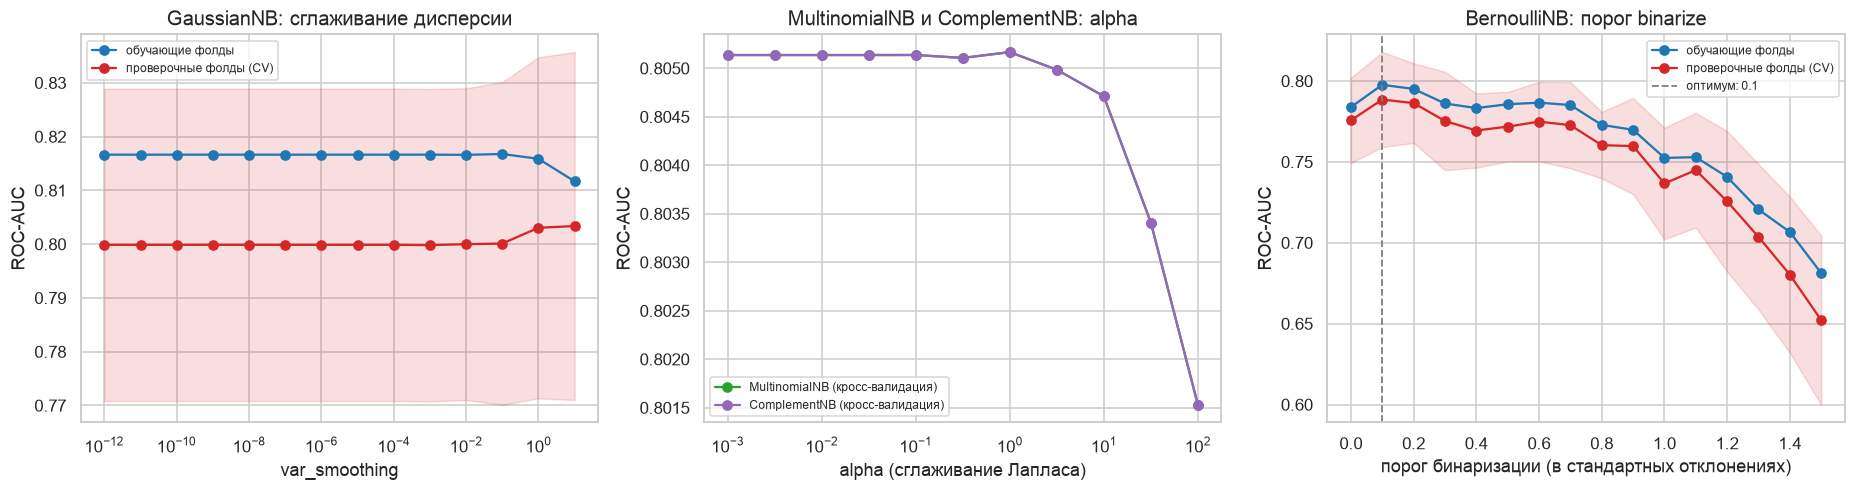

GaussianNB, ROC-AUC (CV) по var_smoothing: 1e-03: 0.7998, 1e-02: 0.8000, 1e-01: 0.8001, 1e+00: 0.8030, 1e+01: 0.8034
GaussianNB: лучший var_smoothing = 1e+01, ROC-AUC (CV) = 0.8034
BernoulliNB: лучший порог binarize = 0.1, ROC-AUC (CV) = 0.7885

Для сравнения: GaussianNB без логарифмирования и винзоризации: ROC-AUC (CV) = 0.7802, ROC-AUC (тестовая выборка) = 0.7871
Лучший вариант по кросс-валидации: MultinomialNB (MinMax [0,1])


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

vs_grid = np.logspace(-12, 1, 14)
tr, va = validation_curve(GaussianNB(), X_train, y_train, param_name="var_smoothing",
                          param_range=vs_grid, cv=cv, scoring="roc_auc")
plot_curve(axes[0], vs_grid, tr, va, "var_smoothing", "GaussianNB: сглаживание дисперсии", logx=True)

alpha_grid = np.logspace(-3, 2, 11)
for est, color, label in [(MultinomialNB(), "#2ca02c", "MultinomialNB"), (ComplementNB(), "#9467bd", "ComplementNB")]:
    _, va_a = validation_curve(est, X_train_mm, y_train, param_name="alpha", param_range=alpha_grid,
                               cv=cv, scoring="roc_auc")
    axes[1].plot(alpha_grid, va_a.mean(1), "o-", color=color, label=f"{label} (кросс-валидация)")
axes[1].set_xscale("log")
axes[1].set_xlabel("alpha (сглаживание Лапласа)")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_title("MultinomialNB и ComplementNB: alpha")
axes[1].legend(fontsize=8)

bin_grid = np.round(np.linspace(0.0, 1.5, 16), 2)   # в sklearn binarize >= 0
tr_b, va_b = validation_curve(BernoulliNB(), X_train, y_train, param_name="binarize",
                              param_range=bin_grid, cv=cv, scoring="roc_auc")
best_bin = bin_grid[va_b.mean(1).argmax()]
plot_curve(axes[2], bin_grid, tr_b, va_b, "порог бинаризации (в стандартных отклонениях)",
           "BernoulliNB: порог binarize", best=best_bin)
plt.tight_layout()
plt.show()

nb_grid = GridSearchCV(GaussianNB(), {"var_smoothing": vs_grid}, cv=cv, scoring="roc_auc").fit(X_train, y_train)
print("GaussianNB, ROC-AUC (CV) по var_smoothing:",
      ", ".join(f"{v:.0e}: {a:.4f}" for v, a in zip(vs_grid, va.mean(1)) if v >= 1e-3))
print(f"GaussianNB: лучший var_smoothing = {nb_grid.best_params_['var_smoothing']:.0e}, "
      f"ROC-AUC (CV) = {nb_grid.best_score_:.4f}")
print(f"BernoulliNB: лучший порог binarize = {best_bin}, ROC-AUC (CV) = {va_b.mean(1).max():.4f}")

# Исследование: GaussianNB на признаках без логарифмирования и винзоризации (только стандартизация)
raw_scaler = StandardScaler().fit(X_train_raw)
gnb_raw = GaussianNB().fit(raw_scaler.transform(X_train_raw), y_train)
auc_raw = roc_auc_score(y_test, gnb_raw.predict_proba(raw_scaler.transform(X_test_raw))[:, 1])
cv_raw = cross_val_score(GaussianNB(), raw_scaler.transform(X_train_raw), y_train, cv=cv, scoring="roc_auc").mean()
print(f"\nДля сравнения: GaussianNB без логарифмирования и винзоризации: ROC-AUC (CV) = {cv_raw:.4f}, "
      f"ROC-AUC (тестовая выборка) = {auc_raw:.4f}")

best_nb_name = nb_df.loc[nb_df["ROC-AUC (CV)"].idxmax(), "Модель"]
print(f"Лучший вариант по кросс-валидации: {best_nb_name}")

### Пояснение к настройке наивного байесовского классификатора

- `var_smoothing` (GaussianNB): при значениях от $10^{-12}$ до $10^{-1}$ ROC-AUC при кросс-валидации практически не меняется (0.7998–0.8001), поскольку после стандартизации все дисперсии близки к 1 и малая добавка на них не влияет. При значениях 1 и 10 ROC-AUC растёт до 0.8030 и 0.8034. Причина в том, что к дисперсиям каждого признака добавляется величина $\varepsilon = \text{var\_smoothing}\cdot\max_j \sigma^2_j \approx 10$, после чего дисперсии в обоих классах становятся почти одинаковыми. Логарифм отношения правдоподобий тогда становится линейной функцией $x$, и модель фактически превращается в линейный классификатор «ближайший центроид», аналогичный LDA с диагональной ковариационной матрицей. Таким образом, подбор параметра показывает, что для данных линейная граница лучше квадратичной, которую строит GaussianNB по умолчанию. Оптимум находится на краю сетки, однако дальнейшее увеличение параметра уже не меняет ранжирование объектов.
- Побочный эффект сильного сглаживания: правдоподобия становятся почти одинаковыми, и решение начинает определять априорная вероятность класса (53.7% хороших вин). Поэтому настроенная модель значительно чаще предсказывает класс «хорошее»: на тестовой выборке Recall вырос с 0.615 до 0.862, Precision снизился с 0.788 до 0.676, F1 увеличился с 0.691 до 0.758, а Accuracy не изменилась (0.706).
- `alpha` (MultinomialNB, ComplementNB): ROC-AUC остаётся на уровне 0.805 при $\alpha \le 1$ и снижается до 0.8015 только при $\alpha = 100$, когда сглаживание подавляет различия между классами. Влияние параметра минимально.
- `binarize` (BernoulliNB): лучший порог равен 0.1 стандартного отклонения (ROC-AUC 0.789 при кросс-валидации). При росте порога качество быстро падает, до 0.65 при пороге 1.5, поскольку большинство значений признака оказывается ниже порога и бинарный признак почти не меняется.
- Влияние предобработки: GaussianNB на признаках без винзоризации и логарифмирования (только стандартизация) даёт ROC-AUC 0.780 при кросс-валидации и 0.787 на тестовой выборке, то есть на 0.020 и 0.005 ниже. Логарифмирование приближает распределения к нормальному, что соответствует предположению модели.

In [9]:
nb_def = GaussianNB().fit(X_train, y_train)
results_default.append(evaluate(nb_def, X_test, "Наивный Байес"))
nb_best = nb_grid.best_estimator_
results_tuned.append(evaluate(nb_best, X_test, "Наивный Байес"))
tuned_models["Наивный Байес"] = (nb_best, X_test)
print("GaussianNB: до и после настройки")
display(compare_rows("Наивный Байес"))

GaussianNB: до и после настройки


,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.7059,0.7882,0.6147,0.6907,0.7915
Настроенная,0.7059,0.6763,0.8624,0.7581,0.8060


### 5.2. Дерево решений

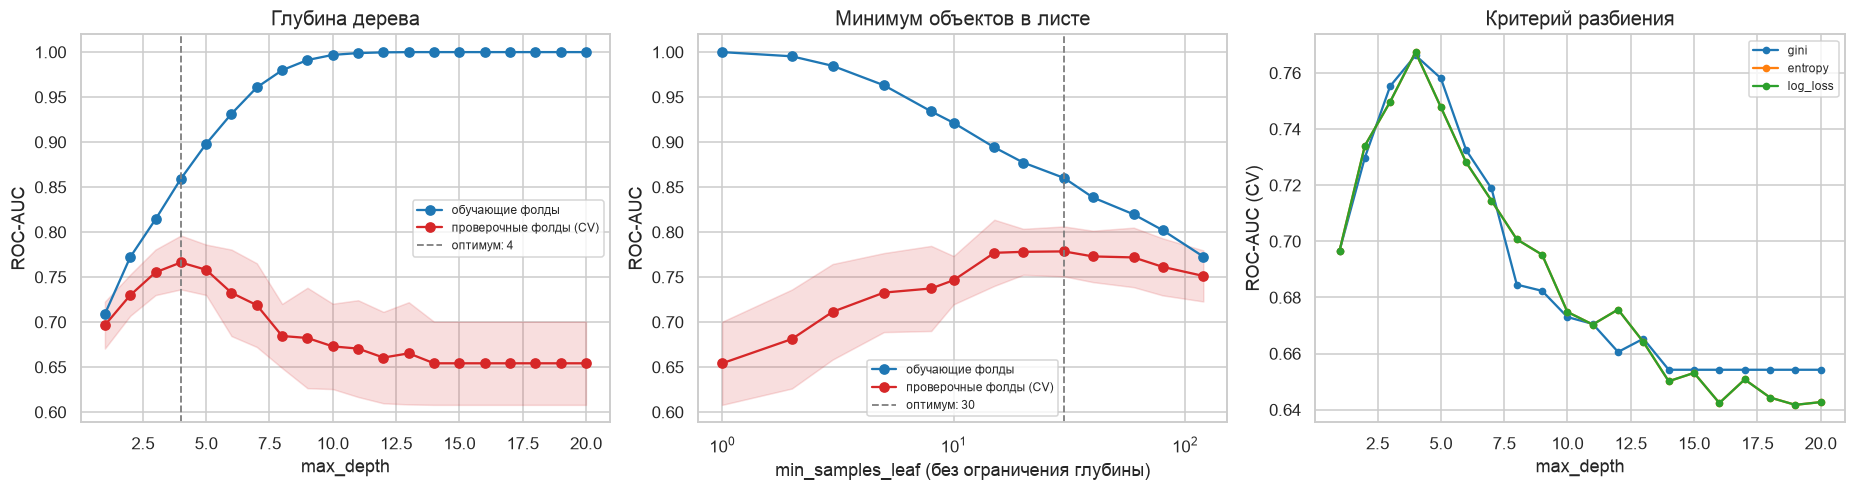

Кривые валидации дерева (ROC-AUC, среднее по фолдам):


max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
обучающие,0.709,0.772,0.814,0.859,0.898,0.931,0.961,0.980,0.991,0.997,0.999,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
проверочные (CV),0.697,0.730,0.755,0.766,0.758,0.733,0.719,0.685,0.682,0.673,0.671,0.661,0.665,0.654,0.654,0.654,0.654,0.654,0.654,0.654


min_samples_leaf,1,2,3,5,8,10,15,20,30,40,60,80,120
обучающие,1.000,0.995,0.985,0.963,0.934,0.921,0.894,0.877,0.860,0.838,0.820,0.802,0.773
проверочные (CV),0.654,0.681,0.711,0.733,0.737,0.747,0.777,0.778,0.779,0.773,0.772,0.761,0.751


Перебрано комбинаций: 224
Лучшие параметры: {'class_weight': None, 'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 15}
ROC-AUC (CV) = 0.7864


param_criterion,param_max_depth,param_min_samples_leaf,param_class_weight,ROC-AUC (CV),СКО
gini,6,15,None,0.786400,0.028800
gini,6,30,balanced,0.786300,0.021200
gini,5,20,None,0.786200,0.035600
gini,8,30,balanced,0.785800,0.020300
gini,10,30,balanced,0.785800,0.020300
gini,None,30,balanced,0.785800,0.020300
gini,7,30,balanced,0.785800,0.020300
gini,6,20,None,0.784700,0.035900


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

depth_grid = np.arange(1, 21)
tr, va = validation_curve(DecisionTreeClassifier(random_state=SEED), X_train, y_train,
                          param_name="max_depth", param_range=depth_grid, cv=cv, scoring="roc_auc")
plot_curve(axes[0], depth_grid, tr, va, "max_depth", "Глубина дерева", best=int(depth_grid[va.mean(1).argmax()]))

leaf_grid = np.array([1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 60, 80, 120])
tr_l, va_l = validation_curve(DecisionTreeClassifier(random_state=SEED), X_train, y_train,
                              param_name="min_samples_leaf", param_range=leaf_grid, cv=cv, scoring="roc_auc")
plot_curve(axes[1], leaf_grid, tr_l, va_l, "min_samples_leaf (без ограничения глубины)",
           "Минимум объектов в листе", logx=True, best=int(leaf_grid[va_l.mean(1).argmax()]))

for crit, color in [("gini", "#1f77b4"), ("entropy", "#ff7f0e"), ("log_loss", "#2ca02c")]:
    _, va_c = validation_curve(DecisionTreeClassifier(criterion=crit, random_state=SEED), X_train, y_train,
                               param_name="max_depth", param_range=depth_grid, cv=cv, scoring="roc_auc")
    axes[2].plot(depth_grid, va_c.mean(1), "o-", ms=4, color=color, label=crit)
axes[2].set_xlabel("max_depth")
axes[2].set_ylabel("ROC-AUC (CV)")
axes[2].set_title("Критерий разбиения")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Кривые валидации дерева (ROC-AUC, среднее по фолдам):")
display(pd.DataFrame({"обучающие": tr.mean(1), "проверочные (CV)": va.mean(1)}, index=depth_grid)
        .rename_axis("max_depth").T.round(3))
display(pd.DataFrame({"обучающие": tr_l.mean(1), "проверочные (CV)": va_l.mean(1)}, index=leaf_grid)
        .rename_axis("min_samples_leaf").T.round(3))

dt_params = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 7, 8, 10, None],
    "min_samples_leaf": [1, 5, 10, 15, 20, 30, 40],
    "class_weight": [None, "balanced"],
}
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED), dt_params, cv=cv,
                       scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print(f"Перебрано комбинаций: {len(dt_grid.cv_results_['params'])}")
print(f"Лучшие параметры: {dt_grid.best_params_}")
print(f"ROC-AUC (CV) = {dt_grid.best_score_:.4f}")
top = pd.DataFrame(dt_grid.cv_results_).sort_values("rank_test_score").head(8)
top["param_class_weight"] = top["param_class_weight"].fillna("None").astype(str)
top["param_max_depth"] = top["param_max_depth"].fillna("None").astype(str)
display(top[["param_criterion", "param_max_depth", "param_min_samples_leaf", "param_class_weight",
             "mean_test_score", "std_test_score"]].round(4).rename(columns={
    "mean_test_score": "ROC-AUC (CV)", "std_test_score": "СКО"}).style.hide(axis="index"))

### Пояснение к настройке дерева решений

- Глубина (`max_depth`): наблюдается типичная картина переобучения. На обучающих фолдах ROC-AUC возрастает от 0.709 при глубине 1 до 1.000 при глубине 12 и более – дерево запоминает обучающую выборку. На проверочных фолдах максимум (0.766) достигается при глубине 4, после чего качество снижается до 0.654 для дерева без ограничений.
- Минимальное число объектов в листе (`min_samples_leaf`, без ограничения глубины): при значении 1 дерево переобучено (0.654 на проверочных фолдах), при увеличении до 15–30 ROC-AUC растёт до 0.777–0.779, а при 80–120 начинается недообучение (0.761 и 0.751). Этот параметр регуляризует дерево эффективнее глубины: листья с 15–30 объектами дают более надёжные оценки вероятности класса, чем листья с одним-двумя объектами.
- Критерий разбиения: кривые для Gini и энтропии (`entropy` и `log_loss` – один и тот же критерий) практически совпадают, максимум для всех трёх (около 0.767) достигается при глубине 4. Выбор критерия на качество почти не влияет.
- Совместный перебор 224 комбинаций с помощью `GridSearchCV`: лучшая модель – критерий Gini, глубина 6, не менее 15 объектов в листе, без весов классов (ROC-AUC 0.786 при кросс-валидации). Восемь лучших комбинаций различаются не более чем на 0.002, тогда как стандартное отклонение по фолдам составляет 0.02–0.04. Следовательно, существует широкая область почти равноценных параметров; главное – ограничить сложность дерева.

Дерево по умолчанию: глубина 14, листьев 145
Настроенное дерево:  глубина 6, листьев 32


,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.6520,0.7021,0.6055,0.6502,0.6554
Настроенная,0.7402,0.7692,0.7339,0.7512,0.8056


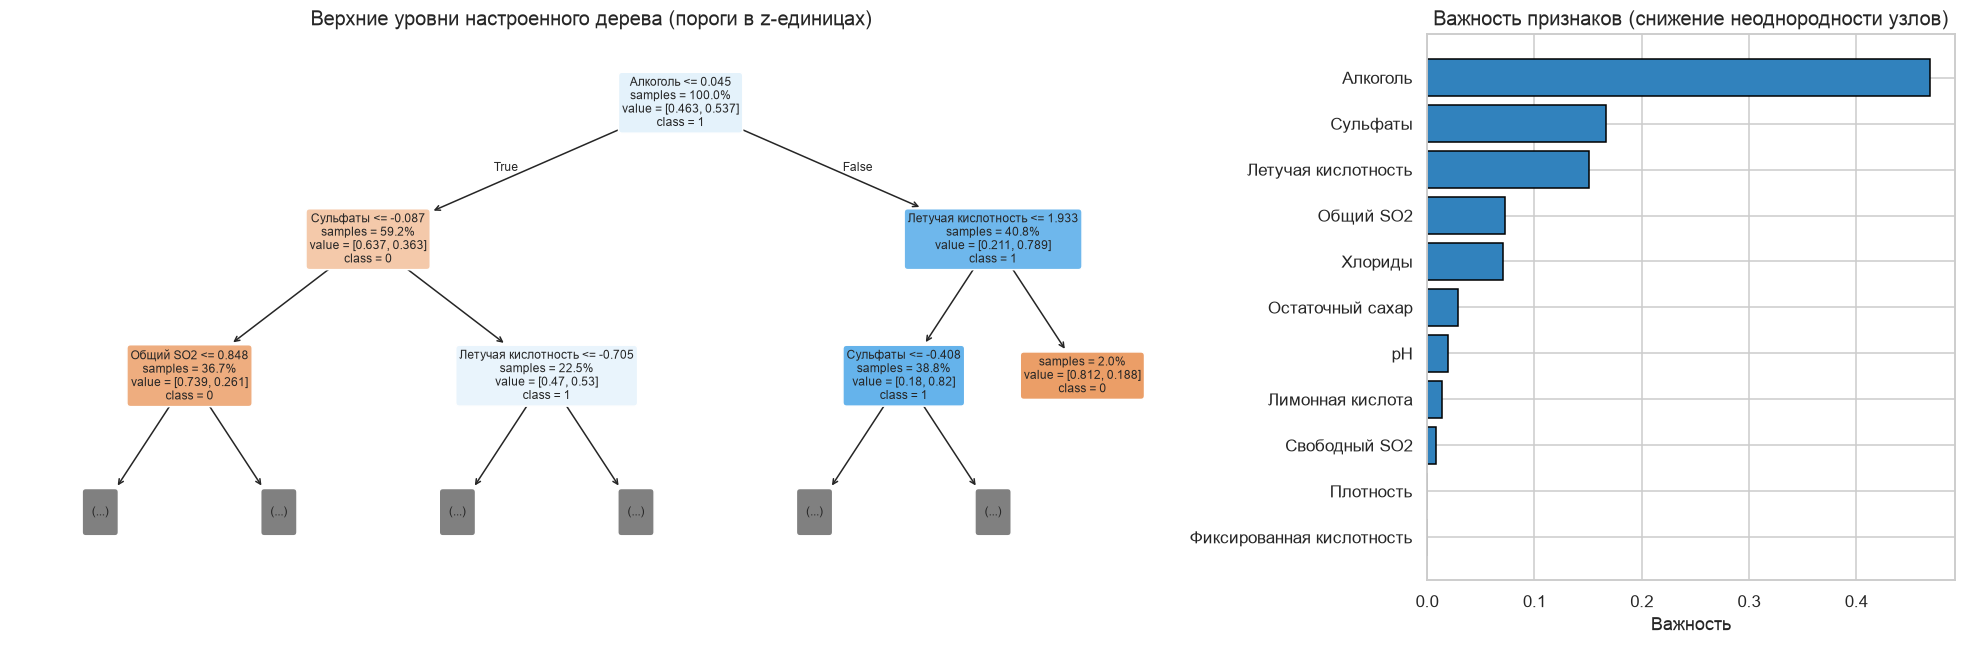

In [11]:
dt_def = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
results_default.append(evaluate(dt_def, X_test, "Дерево решений"))
dt_best = dt_grid.best_estimator_
results_tuned.append(evaluate(dt_best, X_test, "Дерево решений"))
tuned_models["Дерево решений"] = (dt_best, X_test)
print(f"Дерево по умолчанию: глубина {dt_def.get_depth()}, листьев {dt_def.get_n_leaves()}")
print(f"Настроенное дерево:  глубина {dt_best.get_depth()}, листьев {dt_best.get_n_leaves()}")
display(compare_rows("Дерево решений"))

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [2.2, 1]})
plot_tree(dt_best, max_depth=2, feature_names=final_features, class_names=["0", "1"], filled=True,
          rounded=True, fontsize=8, ax=axes[0], impurity=False, proportion=True)
axes[0].set_title("Верхние уровни настроенного дерева (пороги в z-единицах)")
imp = pd.Series(dt_best.feature_importances_, index=final_features).sort_values()
axes[1].barh(imp.index, imp.values, color="#3182bd", edgecolor="black")
axes[1].set_title("Важность признаков (снижение неоднородности узлов)")
axes[1].set_xlabel("Важность")
plt.tight_layout()
plt.show()

### Пояснение к структуре дерева

Для дерева решений настройка гиперпараметров дала наибольший эффект среди всех методов. Дерево с параметрами по умолчанию имеет глубину 14 и 145 листьев, то есть в среднем по 5–6 обучающих объектов на лист; оно переобучено, и его ROC-AUC на тестовой выборке равен лишь 0.655. Настроенное дерево (глубина 6, 32 листа) повышает ROC-AUC до 0.806 (+0.150), Accuracy – с 0.652 до 0.740, F1 – с 0.650 до 0.751.

Верхние уровни дерева легко интерпретировать:

1. Корневое разбиение выполняется по содержанию алкоголя с порогом 0.045 в z-единицах, что соответствует примерно 10.5% об. Среди вин с меньшим содержанием (59% выборки) хороших лишь 36%, среди вин с большим содержанием (41%) – 79%.
2. Для слабоалкогольных вин следующим признаком становятся сульфаты, затем общий SO2 и летучая кислотность.
3. Для крепких вин разбиение выполняется по летучей кислотности: при очень высоких значениях (более 1.93 стандартного отклонения выше среднего, 2% выборки) доля хороших вин падает с 79% до 19%.

Важность признаков согласуется с корреляционным анализом: алкоголь (≈ 0.47), сульфаты (≈ 0.17) и летучая кислотность (≈ 0.15) вместе обеспечивают около 80% снижения неоднородности. Плотность и фиксированная кислотность в настроенном дереве не используются: их информация уже содержится в коррелированных с ними признаках (алкоголь, pH, лимонная кислота).

### 5.3. Линейный дискриминантный анализ

LDA: РЕШАТЕЛИ И АВТОМАТИЧЕСКОЕ СЖАТИЕ (Ledoit–Wolf)


Модель,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC (CV)
"solver=svd, shrinkage=None",0.740200,0.804300,0.678900,0.736300,0.818200,0.824900
"solver=lsqr, shrinkage=None",0.740200,0.804300,0.678900,0.736300,0.818200,0.824900
"solver=eigen, shrinkage=None",0.740200,0.804300,0.678900,0.736300,0.818200,0.824900
"solver=lsqr, shrinkage=auto",0.730400,0.793500,0.669700,0.726400,0.818800,0.826100
"solver=eigen, shrinkage=auto",0.730400,0.793500,0.669700,0.726400,0.818800,0.826100


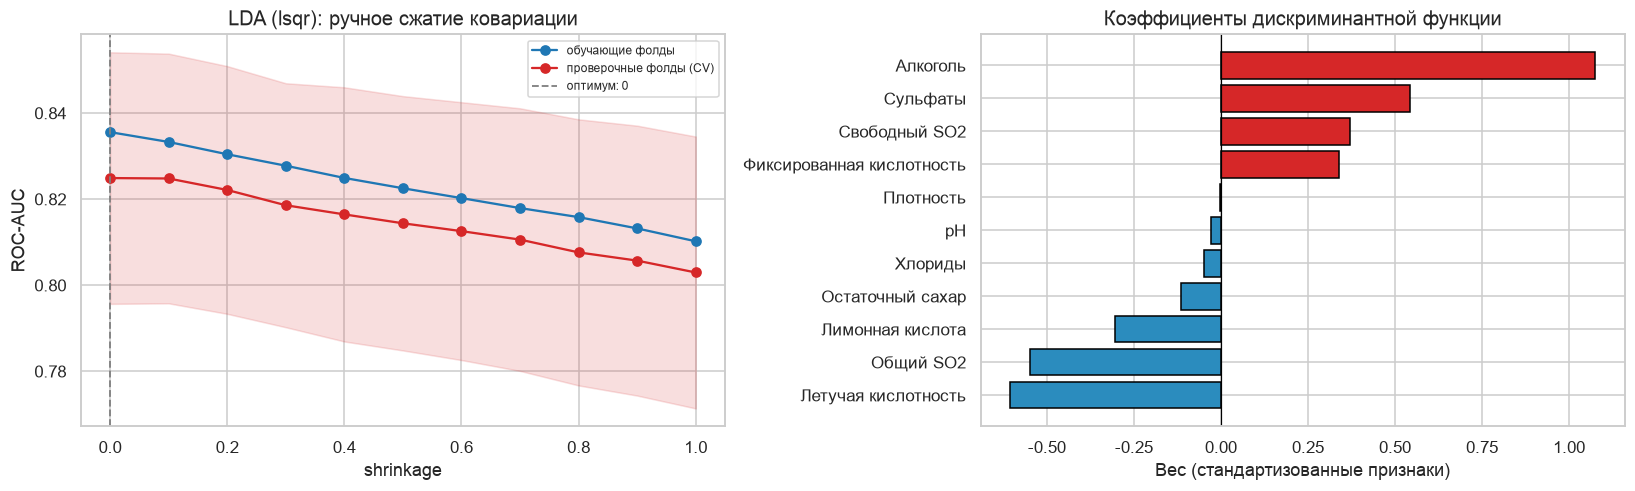

Лучшие параметры LDA: {'shrinkage': 'auto', 'solver': 'lsqr'}, ROC-AUC (CV) = 0.8261
Коэффициенты дискриминантной функции:


,Алкоголь,Летучая кислотность,Общий SO2,Сульфаты,Свободный SO2,Фиксированная кислотность,Лимонная кислота,Остаточный сахар,Хлориды,pH,Плотность
Вес,1.076,-0.607,-0.548,0.544,0.372,0.338,-0.304,-0.113,-0.048,-0.027,-0.001


In [12]:
rows = []
for solver, shrink in [("svd", None), ("lsqr", None), ("eigen", None), ("lsqr", "auto"), ("eigen", "auto")]:
    lda = LinearDiscriminantAnalysis(solver=solver, shrinkage=shrink)
    cv_auc = cross_val_score(lda, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    lda.fit(X_train, y_train)
    r = evaluate(lda, X_test, f"solver={solver}, shrinkage={shrink}")
    r["ROC-AUC (CV)"] = cv_auc
    rows.append(r)
print("LDA: РЕШАТЕЛИ И АВТОМАТИЧЕСКОЕ СЖАТИЕ (Ledoit–Wolf)")
display(pd.DataFrame(rows).round(4).style.hide(axis="index"))

shrink_grid = np.round(np.linspace(0, 1, 11), 1)
tr, va = validation_curve(LinearDiscriminantAnalysis(solver="lsqr"), X_train, y_train,
                          param_name="shrinkage", param_range=shrink_grid, cv=cv, scoring="roc_auc")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
plot_curve(axes[0], shrink_grid, tr, va, "shrinkage", "LDA (lsqr): ручное сжатие ковариации",
           best=float(shrink_grid[va.mean(1).argmax()]))

lda_grid = GridSearchCV(LinearDiscriminantAnalysis(), [
    {"solver": ["svd"]},
    {"solver": ["lsqr", "eigen"], "shrinkage": [None, "auto", 0.01, 0.05, 0.1, 0.2, 0.3, 0.5]},
], cv=cv, scoring="roc_auc").fit(X_train, y_train)
lda_best = lda_grid.best_estimator_
coef = pd.Series(lda_best.coef_[0], index=final_features).sort_values()
axes[1].barh(coef.index, coef.values, color=np.where(coef.values > 0, "#d62728", "#2b8cbe"), edgecolor="black")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Коэффициенты дискриминантной функции")
axes[1].set_xlabel("Вес (стандартизованные признаки)")
plt.tight_layout()
plt.show()
print(f"Лучшие параметры LDA: {lda_grid.best_params_}, ROC-AUC (CV) = {lda_grid.best_score_:.4f}")
print("Коэффициенты дискриминантной функции:")
display(coef.sort_values(key=abs, ascending=False).round(3).rename("Вес").to_frame().T)

### Пояснение к линейному дискриминантному анализу

- Методы решения `svd`, `lsqr` и `eigen` без сжатия дают идентичный результат (ROC-AUC 0.8249 при кросс-валидации, 0.8182 на тестовой выборке), так как они по-разному вычисляют одно и то же решение.
- Автоматическое сжатие ковариационной матрицы по Ледуа–Вольфу (`shrinkage='auto'`) незначительно повышает ROC-AUC при кросс-валидации (0.8261) и выбирается `GridSearchCV` как лучший вариант. При 814 обучающих объектах и 11 признаках ковариационная матрица оценивается достаточно надёжно, поэтому сжатие почти не требуется.
- Кривая для ручного коэффициента сжатия монотонно убывает: от 0.825 при коэффициенте 0 до 0.803 при коэффициенте 1, когда ковариационная матрица заменяется диагональной. Учёт корреляций между признаками (например, между свободным и общим SO2, фиксированной кислотностью и pH) улучшает модель.
- Коэффициенты дискриминантной функции (для стандартизованных признаков их можно сравнивать между собой): наибольший положительный вклад вносит алкоголь (+1.08), затем сульфаты (+0.54), свободный SO2 (+0.37) и фиксированная кислотность (+0.34); отрицательный – летучая кислотность (−0.61), общий SO2 (−0.55) и лимонная кислота (−0.30).
- Некоторые знаки отражают мультиколлинеарность. Свободный SO2 имеет положительный вес, а общий SO2 – отрицательный; поскольку они сильно коррелированы (+0.79), эту пару следует понимать как отрицательный вклад связанного SO2 (разности общего и свободного). Лимонная кислота по отдельности положительно связана с качеством (+0.155), но в модели получает отрицательный вес, так как её полезная информация уже учтена через летучую и фиксированную кислотность. Плотность и pH имеют практически нулевые веса.

In [13]:
lda_def = LinearDiscriminantAnalysis().fit(X_train, y_train)
results_default.append(evaluate(lda_def, X_test, "LDA"))
results_tuned.append(evaluate(lda_best, X_test, "LDA"))
tuned_models["LDA"] = (lda_best, X_test)
display(compare_rows("LDA"))

,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.7402,0.8043,0.6789,0.7363,0.8182
Настроенная,0.7304,0.7935,0.6697,0.7264,0.8188


### 5.4. Метод опорных векторов

In [14]:
rows = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    t0 = time.time()
    svm = SVC(kernel=kernel, C=1.0, random_state=SEED, max_iter=200000).fit(X_train, y_train)
    r = evaluate(svm, X_test, kernel)
    r["ROC-AUC (CV)"] = cross_val_score(SVC(kernel=kernel, C=1.0, max_iter=200000), X_train, y_train,
                                        cv=cv, scoring="roc_auc").mean()
    r["Опорных векторов"] = int(svm.n_support_.sum())
    r["Время обучения, с"] = time.time() - t0
    rows.append(r)
print("SVM: СРАВНЕНИЕ ЯДЕР (C = 1, gamma = 'scale')")
display(pd.DataFrame(rows).rename(columns={"Модель": "Ядро"}).round(4).style.hide(axis="index"))

SVM: СРАВНЕНИЕ ЯДЕР (C = 1, gamma = 'scale')


Ядро,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC (CV),Опорных векторов,"Время обучения, с"
linear,0.735300,0.802200,0.669700,0.730000,0.819500,0.825400,465,0.044000
poly,0.705900,0.757900,0.660600,0.705900,0.804100,0.800900,551,0.035300
rbf,0.740200,0.804300,0.678900,0.736300,0.811300,0.818500,505,0.038900
sigmoid,0.754900,0.798000,0.724800,0.759600,0.790000,0.732600,380,0.036100


### Пояснение к сравнению ядер SVM

- Линейное ядро при $C = 1$ обеспечивает наибольший ROC-AUC при кросс-валидации (0.825) и на тестовой выборке (0.820). Это ещё одно указание на то, что граница между классами близка к линейной.
- RBF-ядро с параметрами по умолчанию немного уступает линейному (0.819 при кросс-валидации), но, как показано ниже, после настройки $C$ и $\gamma$ становится лучшим.
- Полиномиальное ядро третьей степени даёт 0.801, сигмоидальное – 0.733 при кросс-валидации. У сигмоидального ядра на тестовой выборке наибольшая Accuracy (0.755), но это случайность малой выборки: по кросс-валидации оно худшее, и ориентироваться следует на него.
- Число опорных векторов велико: от 380 до 551, то есть 47–68% обучающей выборки. Многие объекты лежат внутри зазора или нарушают его, что говорит о сильном перекрытии классов.
- Время обучения на 814 объектах не превышает 0.05 с для любого ядра.

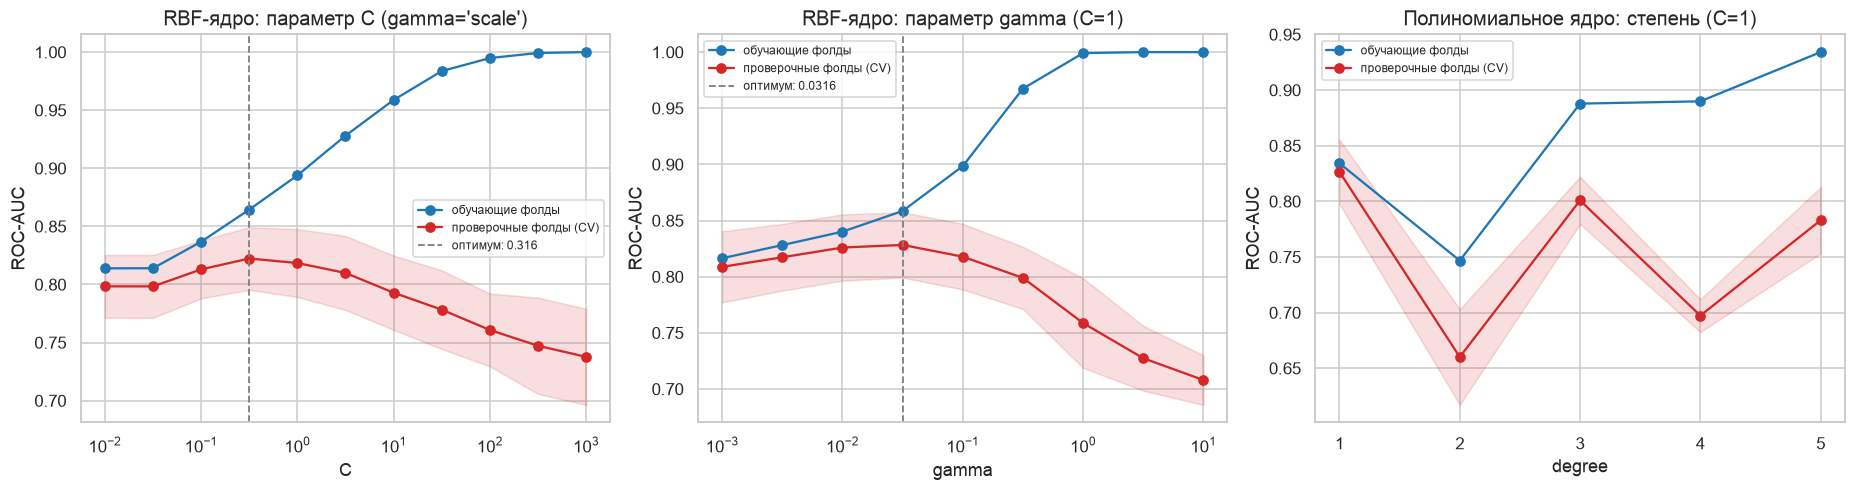

Кривые валидации SVM (ROC-AUC, среднее по фолдам):


C (RBF),0.010,0.032,0.100,0.316,1.000,3.162,10.000,31.623,100.000,316.228,1000.000
обучающие,0.814,0.814,0.837,0.864,0.894,0.928,0.959,0.984,0.995,0.999,1.000
проверочные (CV),0.798,0.798,0.813,0.822,0.818,0.810,0.793,0.778,0.761,0.747,0.738


gamma (RBF),0.0010,0.0032,0.0100,0.0316,0.1000,0.3162,1.0000,3.1623,10.0000
обучающие,0.816,0.828,0.840,0.859,0.898,0.967,0.999,1.000,1.000
проверочные (CV),0.809,0.817,0.826,0.828,0.818,0.799,0.759,0.727,0.708


degree (poly),1,2,3,4,5
обучающие,0.834,0.747,0.888,0.890,0.934
проверочные (CV),0.827,0.660,0.801,0.697,0.783


Лучшие параметры SVM: {'C': 3, 'gamma': 0.02}, ROC-AUC (CV) = 0.8278
ROC-AUC (CV) по сетке C × gamma (gamma='scale' = 1/(11·Var(X)) ≈ 0.091):


param_gamma,0.02,0.05,0.1,0.2,0.5,scale
param_C,,,,,,
0.3,0.8233,0.8250,0.8220,0.8115,0.7893,0.8215
1.0,0.8264,0.8254,0.8178,0.8088,0.7852,0.8185
3.0,0.8278,0.8170,0.8098,0.7920,0.7640,0.8107
10.0,0.8196,0.8083,0.7915,0.7722,0.7527,0.7929
30.0,0.8102,0.7953,0.7756,0.7597,0.7491,0.7800


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
C_grid = np.logspace(-2, 3, 11)
tr, va = validation_curve(SVC(kernel="rbf"), X_train, y_train, param_name="C", param_range=C_grid,
                          cv=cv, scoring="roc_auc", n_jobs=-1)
plot_curve(axes[0], C_grid, tr, va, "C", "RBF-ядро: параметр C (gamma='scale')", logx=True,
           best=float(C_grid[va.mean(1).argmax()]))

g_grid = np.logspace(-3, 1, 9)
tr_g, va_g = validation_curve(SVC(kernel="rbf", C=1.0), X_train, y_train, param_name="gamma",
                              param_range=g_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
plot_curve(axes[1], g_grid, tr_g, va_g, "gamma", "RBF-ядро: параметр gamma (C=1)", logx=True,
           best=float(g_grid[va_g.mean(1).argmax()]))

deg_grid = [1, 2, 3, 4, 5]
tr_d, va_d = validation_curve(SVC(kernel="poly", C=1.0), X_train, y_train, param_name="degree",
                              param_range=deg_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
plot_curve(axes[2], deg_grid, tr_d, va_d, "degree", "Полиномиальное ядро: степень (C=1)")
axes[2].set_xticks(deg_grid)
plt.tight_layout()
plt.show()
print("Кривые валидации SVM (ROC-AUC, среднее по фолдам):")
display(pd.DataFrame({"обучающие": tr.mean(1), "проверочные (CV)": va.mean(1)}, index=np.round(C_grid, 3))
        .rename_axis("C (RBF)").T.round(3))
display(pd.DataFrame({"обучающие": tr_g.mean(1), "проверочные (CV)": va_g.mean(1)}, index=np.round(g_grid, 4))
        .rename_axis("gamma (RBF)").T.round(3))
display(pd.DataFrame({"обучающие": tr_d.mean(1), "проверочные (CV)": va_d.mean(1)}, index=deg_grid)
        .rename_axis("degree (poly)").T.round(3))

svm_grid = GridSearchCV(SVC(kernel="rbf"), {"C": [0.3, 1, 3, 10, 30], "gamma": ["scale", 0.02, 0.05, 0.1, 0.2, 0.5]},
                        cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print(f"Лучшие параметры SVM: {svm_grid.best_params_}, ROC-AUC (CV) = {svm_grid.best_score_:.4f}")
cvr = pd.DataFrame(svm_grid.cv_results_)
cvr["param_gamma"] = cvr["param_gamma"].astype(str)
pivot = cvr.pivot_table(index="param_C", columns="param_gamma", values="mean_test_score")
print("ROC-AUC (CV) по сетке C × gamma (gamma='scale' = 1/(11·Var(X)) ≈ 0.091):")
display(pivot.round(4))

### Пояснение к настройке SVM

- Параметр $C$ (RBF-ядро, `gamma='scale'`): на обучающих фолдах ROC-AUC монотонно растёт с ростом $C$ (с 0.814 до 1.000), а на проверочных максимум (0.822) достигается при $C \approx 0.3$, после чего качество падает до 0.738 при $C = 1000$. При большом $C$ модель стремится классифицировать каждый обучающий объект правильно и переобучается.
- Параметр $\gamma$ (RBF-ядро, $C = 1$): при малых значениях ядро широкое и граница почти линейна (0.809 при $\gamma = 0.001$); оптимум 0.828 достигается при $\gamma \approx 0.03$; при $\gamma \ge 1$ каждый опорный вектор влияет лишь на ближайшую окрестность, обучающая выборка запоминается полностью (ROC-AUC 1.000 на обучающих фолдах), а качество на проверочных фолдах падает до 0.71.
- Степень полиномиального ядра: нечётные степени (1, 3, 5) дают 0.827, 0.801 и 0.783, а чётные (2, 4) – только 0.660 и 0.697. В `SVC` по умолчанию `coef0 = 0`, поэтому ядро $(\gamma x^\top x')^p$ при чётном $p$ не меняется при замене $x$ на $-x$ и не может различить противоположные направления отклонения признаков от среднего (например, высокое и низкое содержание алкоголя). Степень 1 соответствует линейному ядру и даёт лучший результат.
- Совместная сетка $C \times \gamma$ (30 комбинаций): лучшая модель – $C = 3$, $\gamma = 0.02$ (ROC-AUC 0.828 при кросс-валидации). Таблица показывает характерную диагональную структуру: чем больше $\gamma$, тем меньше должен быть $C$, и наоборот. Значение $\gamma = 0.02$ в 4.5 раза меньше значения по умолчанию (`scale` = $1/(11\cdot 1) \approx 0.091$), то есть оптимальная граница более гладкая, чем по умолчанию.
- На тестовой выборке настройка повысила ROC-AUC с 0.811 до 0.829 (+0.017), Accuracy – с 0.740 до 0.750, F1 – с 0.736 до 0.749.

In [16]:
svm_def = SVC().fit(X_train, y_train)
results_default.append(evaluate(svm_def, X_test, "SVM"))
svm_best = svm_grid.best_estimator_
results_tuned.append(evaluate(svm_best, X_test, "SVM"))
tuned_models["SVM"] = (svm_best, X_test)
display(compare_rows("SVM"))

,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.7402,0.8043,0.6789,0.7363,0.8113
Настроенная,0.7500,0.8085,0.6972,0.7488,0.8287


### 5.5. Метод k ближайших соседей

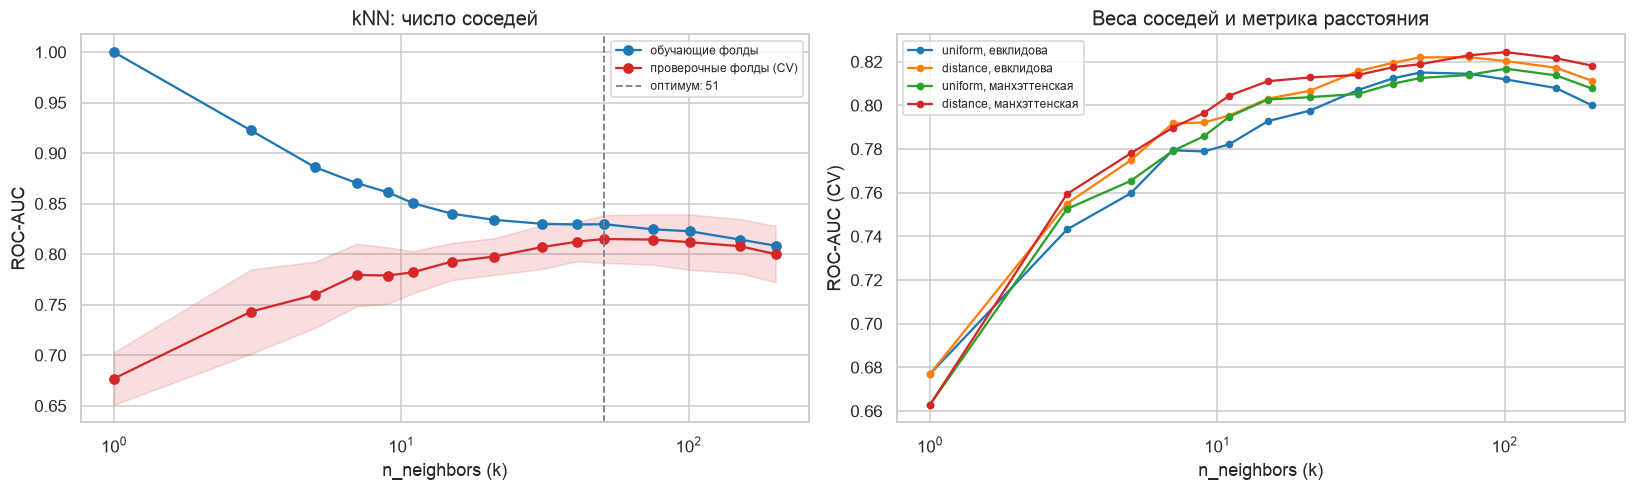

Кривая валидации kNN (uniform, евклидова метрика; ROC-AUC, среднее по фолдам):


k,1,3,5,7,9,11,15,21,31,41,51,75,101,151,201
обучающие,1.000,0.922,0.886,0.870,0.861,0.850,0.840,0.834,0.830,0.829,0.830,0.825,0.823,0.814,0.808
проверочные (CV),0.677,0.743,0.760,0.779,0.779,0.782,0.793,0.798,0.807,0.812,0.815,0.814,0.812,0.808,0.800


Лучшие параметры kNN: {'n_neighbors': 75, 'p': 1, 'weights': 'distance'}, ROC-AUC (CV) = 0.8229
kNN с теми же параметрами без стандартизации: ROC-AUC (тестовая выборка) = 0.8074


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
k_grid = np.array([1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 75, 101, 151, 201])
tr, va = validation_curve(KNeighborsClassifier(), X_train, y_train, param_name="n_neighbors",
                          param_range=k_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
plot_curve(axes[0], k_grid, tr, va, "n_neighbors (k)", "kNN: число соседей", logx=True,
           best=int(k_grid[va.mean(1).argmax()]))

for weights, p, color in [("uniform", 2, "#1f77b4"), ("distance", 2, "#ff7f0e"),
                          ("uniform", 1, "#2ca02c"), ("distance", 1, "#d62728")]:
    _, va_w = validation_curve(KNeighborsClassifier(weights=weights, p=p), X_train, y_train,
                               param_name="n_neighbors", param_range=k_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    axes[1].plot(k_grid, va_w.mean(1), "o-", ms=4, color=color,
                 label=f"{weights}, {'евклидова' if p == 2 else 'манхэттенская'}")
axes[1].set_xscale("log")
axes[1].set_xlabel("n_neighbors (k)")
axes[1].set_ylabel("ROC-AUC (CV)")
axes[1].set_title("Веса соседей и метрика расстояния")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Кривая валидации kNN (uniform, евклидова метрика; ROC-AUC, среднее по фолдам):")
display(pd.DataFrame({"обучающие": tr.mean(1), "проверочные (CV)": va.mean(1)}, index=k_grid)
        .rename_axis("k").T.round(3))

knn_grid = GridSearchCV(KNeighborsClassifier(), {
    "n_neighbors": [9, 15, 21, 31, 41, 51, 75],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print(f"Лучшие параметры kNN: {knn_grid.best_params_}, ROC-AUC (CV) = {knn_grid.best_score_:.4f}")

# Влияние масштабирования: kNN без стандартизации
knn_noscale = KNeighborsClassifier(**knn_grid.best_params_).fit(X_train_p, y_train)
print(f"kNN с теми же параметрами без стандартизации: ROC-AUC (тестовая выборка) = "
      f"{roc_auc_score(y_test, knn_noscale.predict_proba(X_test_p)[:, 1]):.4f}")

### Пояснение к настройке метода k ближайших соседей

- Число соседей $k$: при $k = 1$ модель безошибочно воспроизводит обучающую выборку (ROC-AUC 1.000), но на проверочных фолдах даёт лишь 0.677 – это явное переобучение. С ростом $k$ оценка вероятности усредняется по большему числу соседей и становится устойчивее: 0.760 при $k = 5$ (значение по умолчанию), 0.793 при $k = 15$, максимум 0.815 при $k = 51$. При $k \ge 100$ качество начинает снижаться (0.800 при $k = 201$), так как окрестность охватывает почти треть обучающих объектов фолда (651) и модель теряет локальность.
- Веса и метрика: взвешивание по расстоянию (`distance`) и манхэттенская метрика ($p = 1$) дают лучший результат при больших $k$. Манхэттенское расстояние менее чувствительно к отдельным большим отклонениям по одному признаку, а взвешивание уменьшает влияние дальних соседей и смягчает недостаток больших окрестностей.
- `GridSearchCV`: лучшая модель – $k = 75$, `weights='distance'`, $p = 1$ (ROC-AUC 0.823 при кросс-валидации, тогда как при параметрах по умолчанию 0.760).
- Влияние масштабирования: без стандартизации ROC-AUC на тестовой выборке равен 0.807 против 0.811 со стандартизацией. Разница здесь невелика, поскольку после логарифмирования признаки имеют сравнимый порядок величин; признаки с малым разбросом (например, плотность со стандартным отклонением 0.002) при этом фактически исключаются из расстояния, но они и слабо информативны.
- На тестовой выборке настройка повысила ROC-AUC с 0.800 до 0.811, но Accuracy снизилась с 0.760 до 0.725, а Recall – с 0.771 до 0.697. Модель с $k = 5$ на этих 204 образцах удачнее расположила порог 0.5, однако её ранжирование хуже (ROC-AUC при кросс-валидации 0.760 против 0.823). Разница в Accuracy соответствует 7 образцам, и по кросс-валидации настроенная модель надёжнее.

,Accuracy,Precision,Recall,F1,ROC-AUC
По умолчанию,0.7598,0.7778,0.7706,0.7742,0.8001
Настроенная,0.7255,0.7677,0.6972,0.7308,0.8109


ВЛИЯНИЕ НАСТРОЙКИ: прирост метрик на тестовой выборке (настроенная − по умолчанию)


,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC (CV) настроенной
Модель,,,,,,
Наивный Байес,0.0000,-0.1120,0.2477,0.0673,0.0145,0.8034
Дерево решений,0.0882,0.0671,0.1284,0.1009,0.1503,0.7864
LDA,-0.0098,-0.0109,-0.0092,-0.0100,0.0007,0.8261
SVM,0.0098,0.0042,0.0183,0.0125,0.0174,0.8278
kNN,-0.0343,-0.0101,-0.0734,-0.0434,0.0108,0.8229


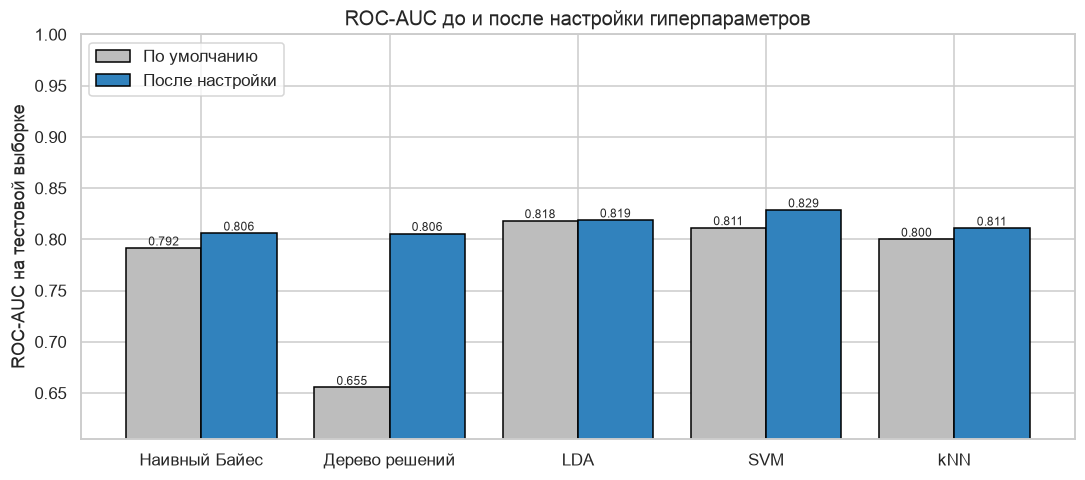

In [18]:
knn_def = KNeighborsClassifier().fit(X_train, y_train)
results_default.append(evaluate(knn_def, X_test, "kNN"))
knn_best = knn_grid.best_estimator_
results_tuned.append(evaluate(knn_best, X_test, "kNN"))
tuned_models["kNN"] = (knn_best, X_test)
display(compare_rows("kNN"))

df_def = pd.DataFrame(results_default).set_index("Модель")
df_tun = pd.DataFrame(results_tuned).set_index("Модель")
cv_best = pd.Series({"Наивный Байес": nb_grid.best_score_, "Дерево решений": dt_grid.best_score_,
                     "LDA": lda_grid.best_score_, "SVM": svm_grid.best_score_, "kNN": knn_grid.best_score_})
print("ВЛИЯНИЕ НАСТРОЙКИ: прирост метрик на тестовой выборке (настроенная − по умолчанию)")
display((df_tun - df_def).assign(**{"ROC-AUC (CV) настроенной": cv_best}).round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(df_def))
b1 = ax.bar(x - 0.2, df_def["ROC-AUC"], 0.4, label="По умолчанию", color="#bdbdbd", edgecolor="black")
b2 = ax.bar(x + 0.2, df_tun["ROC-AUC"], 0.4, label="После настройки", color="#3182bd", edgecolor="black")
ax.bar_label(b1, fmt="%.3f", fontsize=8)
ax.bar_label(b2, fmt="%.3f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(df_def.index)
ax.set_ylim(min(df_def["ROC-AUC"].min(), df_tun["ROC-AUC"].min()) - 0.05, 1.0)
ax.set_ylabel("ROC-AUC на тестовой выборке")
ax.set_title("ROC-AUC до и после настройки гиперпараметров")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Пояснение к влиянию настройки гиперпараметров

| Метод | Лучшие параметры | ROC-AUC (CV) | ΔROC-AUC (тестовая выборка) | Объяснение |
|---|---|---|---|---|
| Дерево решений | Gini, глубина 6, min_samples_leaf = 15 | 0.786 | +0.150 | Дерево по умолчанию сильно переобучено (145 листьев); ограничение сложности даёт наибольший эффект |
| SVM | RBF, $C = 3$, $\gamma = 0.02$ | 0.828 | +0.017 | Более гладкая граница, чем при `gamma='scale'` |
| Наивный Байес | GaussianNB, var_smoothing = 10 | 0.803 | +0.015 | Сильное сглаживание делает границу линейной; Recall растёт, Precision падает |
| kNN | $k = 75$, `distance`, $p = 1$ | 0.823 | +0.011 | Большая окрестность устраняет переобучение при $k = 5$ |
| LDA | `lsqr`, shrinkage = auto | 0.826 | +0.001 | У модели нет параметров сложности; сжатие ковариации почти не требуется |

Общие выводы:

1. Настройка наиболее важна для гибких непараметрических методов – дерева решений и kNN, – которые с параметрами по умолчанию переобучаются. Для простых моделей с сильными предположениями (LDA, наивный Байес) настройка почти не меняет результат.
2. Во всех случаях оптимальные параметры соответствуют более простой и гладкой модели, чем модель по умолчанию: меньшая глубина дерева, большее число соседей, меньшее $\gamma$, линейная граница в GaussianNB. Это согласуется с тем, что классы сильно перекрываются, а объём выборки невелик (814 обучающих объектов).
3. После настройки ROC-AUC при кросс-валидации у четырёх методов из пяти лежит в узком интервале 0.803–0.828, при этом линейные LDA и SVM с почти линейной RBF-границей находятся в верхней части интервала.

## 6. Нейронная сеть на TensorFlow

Используется полносвязная нейронная сеть (многослойный перцептрон), построенная средствами Keras API:

- Входной слой – 11 стандартизованных признаков (те же, что и для моделей Scikit-Learn).
- Скрытые слои – слои `Dense` с функцией активации (по умолчанию ReLU, $f(z) = \max(0, z)$); при необходимости добавляются слои `Dropout`.
- Выходной слой – один нейрон с сигмоидной функцией активации $\sigma(z) = \frac{1}{1 + e^{-z}}$, выдающий вероятность того, что вино хорошее.
- Функция потерь – бинарная кросс-энтропия $L = -\frac1n\sum_i \left[y_i \ln p_i + (1-y_i)\ln(1-p_i)\right]$.
- Оптимизатор – Adam (адаптивный градиентный спуск с оценками моментов), скорость обучения по умолчанию $10^{-3}$.
- Метрики – accuracy и ROC-AUC, вычисляемые после каждой эпохи.

Из обучающей выборки выделено 20% объектов для валидации: по валидационной выборке сравниваются варианты сети и определяется момент остановки обучения. Тестовая выборка используется только для оценки итоговой модели.

Каждый запуск записывает логи в каталог `logs/fit/<эксперимент>/<вариант>` с помощью `keras.callbacks.TensorBoard`: скалярные метрики (функция потерь, accuracy, ROC-AUC) для обучающей и валидационной выборок, а также гистограммы весов на каждой эпохе.

In [19]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print(f"TensorFlow {tf.__version__}")

LOG_ROOT = "logs/fit"
shutil.rmtree(LOG_ROOT, ignore_errors=True)

# отдельная валидационная выборка из train (20%) – общая для всех экспериментов
X_tr_nn, X_val_nn, y_tr_nn, y_val_nn = train_test_split(
    X_train.values.astype("float32"), y_train.values.astype("float32"),
    test_size=0.20, random_state=SEED, stratify=y_train,
)
X_te_nn = X_test.values.astype("float32")
print(f"NN: train {len(X_tr_nn)}, validation {len(X_val_nn)}, test {len(X_te_nn)}")


def build_model(hidden=(64, 32), activation="relu", dropout=0.0, lr=1e-3):
    model = keras.Sequential([layers.Input(shape=(X_tr_nn.shape[1],))])
    for units in hidden:
        model.add(layers.Dense(units, activation=activation))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model


nn_runs = []      # сводка всех запусков
nn_hist = {}      # истории обучения


def run_experiment(group, name, hidden=(64, 32), activation="relu", dropout=0.0, lr=1e-3,
                   epochs=100, batch_size=32, early_stop=False, verbose=0):
    keras.utils.set_random_seed(SEED)
    model = build_model(hidden, activation, dropout, lr)
    callbacks = [keras.callbacks.TensorBoard(log_dir=f"{LOG_ROOT}/{group}/{name}", histogram_freq=1)]
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=30,
                                                       restore_best_weights=True))
    t0 = time.time()
    h = model.fit(X_tr_nn, y_tr_nn, validation_data=(X_val_nn, y_val_nn), epochs=epochs,
                  batch_size=batch_size, callbacks=callbacks, verbose=verbose)
    elapsed = time.time() - t0
    hist = pd.DataFrame(h.history)
    hist.index += 1
    nn_hist[(group, name)] = hist
    val_loss, val_acc, val_auc = model.evaluate(X_val_nn, y_val_nn, verbose=0)
    nn_runs.append({
        "config": dict(hidden=hidden, activation=activation, dropout=dropout, lr=lr, batch_size=batch_size),
        "Эксперимент": group, "Вариант": name, "Эпох": len(hist), "Параметров": model.count_params(),
        "Лучшая эпоха (val_loss)": int(hist["val_loss"].idxmin()),
        "Мин. val_loss": hist["val_loss"].min(),
        "Макс. val_AUC": hist["val_auc"].max(),
        "val_loss (финал)": val_loss, "val_accuracy": val_acc, "val_AUC": val_auc,
        "Время, с": elapsed,
    })
    return model, hist


def show_group(group, title=None):
    runs = [(n, h) for (g, n), h in nn_hist.items() if g == group]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
    for (n, h), c in zip(runs, sns.color_palette("tab10", len(runs))):
        axes[0].plot(h.index, h["loss"], color=c, label=n)
        axes[1].plot(h.index, h["val_loss"], color=c, label=n)
        axes[2].plot(h.index, h["val_auc"], color=c, label=n)
    for ax, t in zip(axes, ["Потери (обучающая выборка)", "Потери (валидационная выборка)", "ROC-AUC (валидационная выборка)"]):
        ax.set_title(t)
        ax.set_xlabel("Эпоха")
    axes[1].set_ylim(top=min(axes[1].get_ylim()[1], 1.2))
    axes[0].legend(fontsize=8)
    plt.suptitle(title or group, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame([r for r in nn_runs if r["Эксперимент"] == group]).drop(columns=["Эксперимент", "config"])
            .round(4).style.hide(axis="index"))

TensorFlow 2.21.0
NN: train 651, validation 163, test 204


### Пояснение к организации экспериментов

- Обучающая выборка (814 объектов) стратифицированно разделена на 651 объект для обучения сети и 163 – для валидации. Тестовая выборка (204 объекта) в выборе архитектуры не участвует.
- Функция `run_experiment` перед каждым запуском фиксирует seed, поэтому различия между вариантами вызваны только изменением исследуемого гиперпараметра, а не другой начальной инициализацией весов.
- Для каждого запуска сохраняется история метрик по эпохам, минимальное значение `val_loss` и номер эпохи, на которой оно достигнуто, а также значения метрик на валидационной выборке после последней эпохи.
- Варианты сравниваются по минимальному `val_loss`, так как он показывает, насколько хорошо может обобщать данная конфигурация при своевременной остановке обучения. Значения после последней эпохи показывают, насколько сильно сеть переобучается, если обучение не остановить.
- Валидационная выборка мала (163 объекта), поэтому различия в `val_loss` порядка 0.005 и в ROC-AUC порядка 0.005 следует считать несущественными.

In [20]:
base_model = build_model()
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

### Базовая архитектура

| Слой | Размер выхода | Число параметров | Функция активации |
|---|---|---|---|
| Входной | 11 | – | – |
| Dense | 64 | 11·64 + 64 = 768 | ReLU |
| Dense | 32 | 64·32 + 32 = 2 080 | ReLU |
| Dense (выходной) | 1 | 32 + 1 = 33 | sigmoid |
| **Всего** | | **2 881** | |

Число обучаемых параметров (2 881) в 4.4 раза превышает число обучающих объектов (651), поэтому следует ожидать быстрого переобучения. Для проверки этого базовая сеть обучается 300 эпох без ранней остановки.

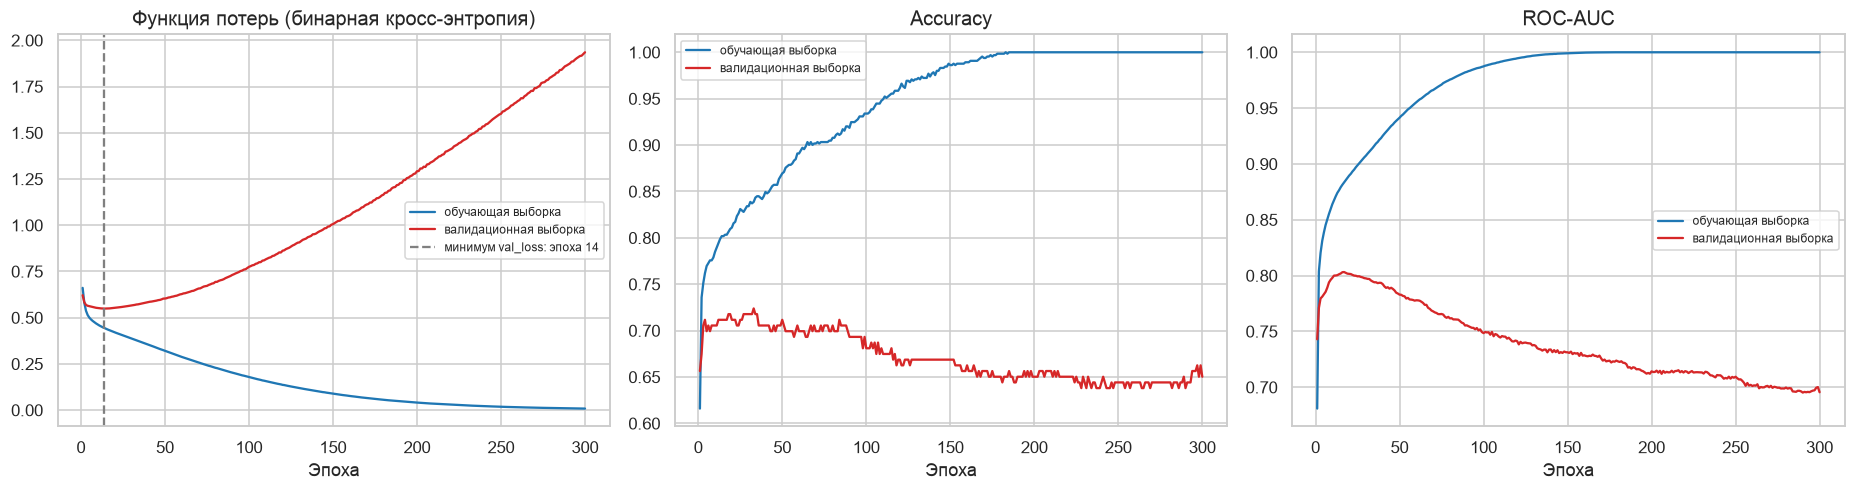

Метрики после N эпох (базовая сеть 64-32, batch 32):


,loss,val_loss,accuracy,val_accuracy,auc,val_auc
Эпох,,,,,,
5,0.5002,0.5621,0.7696,0.6994,0.8387,0.7833
10,0.4629,0.5522,0.7849,0.7055,0.8639,0.7980
20,0.4210,0.5528,0.8111,0.7117,0.8895,0.8016
30,0.3879,0.5660,0.8341,0.7178,0.9074,0.7975
50,0.3208,0.6034,0.8694,0.7117,0.9414,0.7830
75,0.2430,0.6719,0.9032,0.7055,0.9711,0.7656
100,0.1788,0.7749,0.9339,0.6810,0.9874,0.7485
150,0.0893,1.0060,0.9862,0.6687,0.9992,0.7313
200,0.0408,1.2922,1.0000,0.6503,1.0000,0.7142


In [21]:
model_long, hist_long = run_experiment("1_epochs", "300 эпох", epochs=300)
best_ep = int(hist_long["val_loss"].idxmin())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(hist_long.index, hist_long["loss"], label="обучающая выборка", color="#1f77b4")
axes[0].plot(hist_long.index, hist_long["val_loss"], label="валидационная выборка", color="#d62728")
axes[0].axvline(best_ep, color="gray", linestyle="--", label=f"минимум val_loss: эпоха {best_ep}")
axes[0].set_title("Функция потерь (бинарная кросс-энтропия)")
axes[1].plot(hist_long.index, hist_long["accuracy"], label="обучающая выборка", color="#1f77b4")
axes[1].plot(hist_long.index, hist_long["val_accuracy"], label="валидационная выборка", color="#d62728")
axes[1].set_title("Accuracy")
axes[2].plot(hist_long.index, hist_long["auc"], label="обучающая выборка", color="#1f77b4")
axes[2].plot(hist_long.index, hist_long["val_auc"], label="валидационная выборка", color="#d62728")
axes[2].set_title("ROC-AUC")
for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

checkpoints = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300]
print("Метрики после N эпох (базовая сеть 64-32, batch 32):")
display(hist_long.loc[checkpoints, ["loss", "val_loss", "accuracy", "val_accuracy", "auc", "val_auc"]]
        .rename_axis("Эпох").round(4))

### Пояснение к исследованию числа эпох

Базовая сеть (64-32, ReLU, Adam с шагом $10^{-3}$, батч 32) обучалась 300 эпох без ранней остановки.

- Первые 10–15 эпох функция потерь снижается на обеих выборках; минимум `val_loss` (0.549) достигается на 14-й эпохе, когда ROC-AUC на валидационной выборке близок к максимуму (0.798 после 10 эпох и 0.802 после 20).
- Далее сеть переобучается: потери на обучающей выборке продолжают снижаться (0.32 после 50 эпох, 0.04 после 200, 0.008 после 300), а на валидационной – растут (0.603 после 50 эпох, 1.29 после 200, 1.94 после 300).
- После 200 эпох Accuracy и ROC-AUC на обучающей выборке равны 1.0: сеть полностью запомнила 651 обучающий объект. При этом на валидационной выборке Accuracy снизилась с 0.71–0.72 до 0.65, а ROC-AUC – с 0.80 до 0.70.
- Рост `val_loss` заметно опережает падение валидационной Accuracy: сначала сеть становится чрезмерно уверенной в ошибочных предсказаниях (вероятности близки к 0 или 1), и лишь затем начинают меняться сами предсказанные классы.

Вывод: число эпох – ключевой регуляризующий параметр для данной задачи. Оптимум находится в районе 10–20 эпох; обучение дольше без регуляризации ухудшает модель. В итоговой модели число эпох определяет `EarlyStopping`.

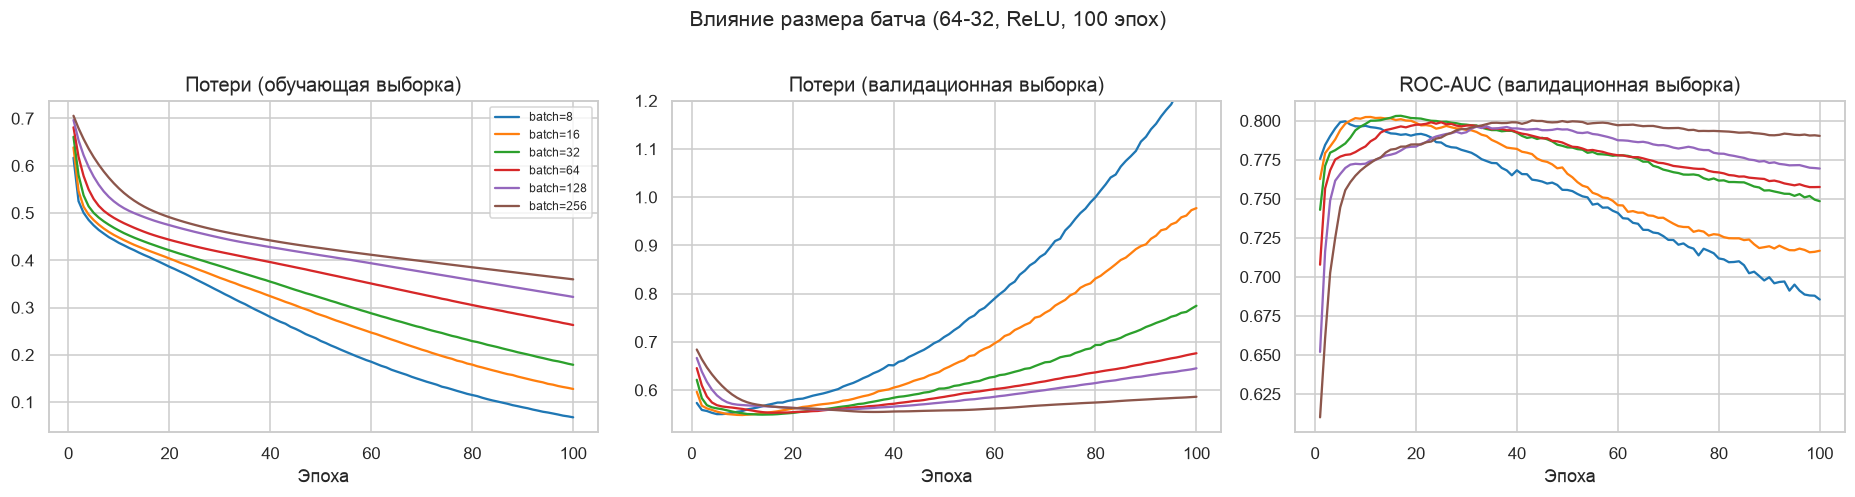

Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,Макс. val_AUC,val_loss (финал),val_accuracy,val_AUC,"Время, с"
batch=8,100,2881,5,0.550200,0.799600,1.268500,0.613500,0.685500,6.457800
batch=16,100,2881,10,0.548400,0.802400,0.977200,0.644200,0.716700,4.912600
batch=32,100,2881,14,0.549200,0.803200,0.774900,0.681000,0.748500,4.122700
batch=64,100,2881,16,0.553100,0.799000,0.676400,0.699400,0.757600,3.729900
batch=128,100,2881,28,0.559000,0.796400,0.645200,0.693300,0.769400,3.573100
batch=256,100,2881,36,0.554700,0.800200,0.586200,0.705500,0.790300,3.487100


In [22]:
for bs in [8, 16, 32, 64, 128, 256]:
    run_experiment("2_batch", f"batch={bs}", batch_size=bs, epochs=100)
show_group("2_batch", title="Влияние размера батча (64-32, ReLU, 100 эпох)")

### Пояснение к исследованию размера батча

Архитектура 64-32, 100 эпох; варьируется только размер батча.

- Малый батч соответствует большому числу обновлений весов за эпоху (82 обновления при батче 8 и 3 – при батче 256). Поэтому с ростом батча минимум `val_loss` достигается всё позже: на 5-й эпохе при батче 8, 14-й при 32, 28-й при 128 и 36-й при 256.
- Минимальное значение `val_loss` почти не зависит от размера батча (0.548–0.559), а максимальный ROC-AUC на валидационной выборке лежит в пределах 0.796–0.803. Различия сравнимы с шумом малой валидационной выборки.
- Сильно различается степень переобучения к 100-й эпохе: при батче 8 `val_loss` вырастает до 1.27, а ROC-AUC падает до 0.686; при батче 256 сеть за то же число эпох выполнила в 32 раза меньше обновлений, и `val_loss` равен лишь 0.586 (ROC-AUC 0.790). Таким образом, при фиксированном числе эпох размер батча фактически задаёт продолжительность обучения.
- Время обучения 100 эпох уменьшается с 6.4 с (батч 8) до 3.4 с (батч 256).

Размер батча 32 выбран для дальнейших экспериментов как компромисс между скоростью сходимости и стабильностью градиента.

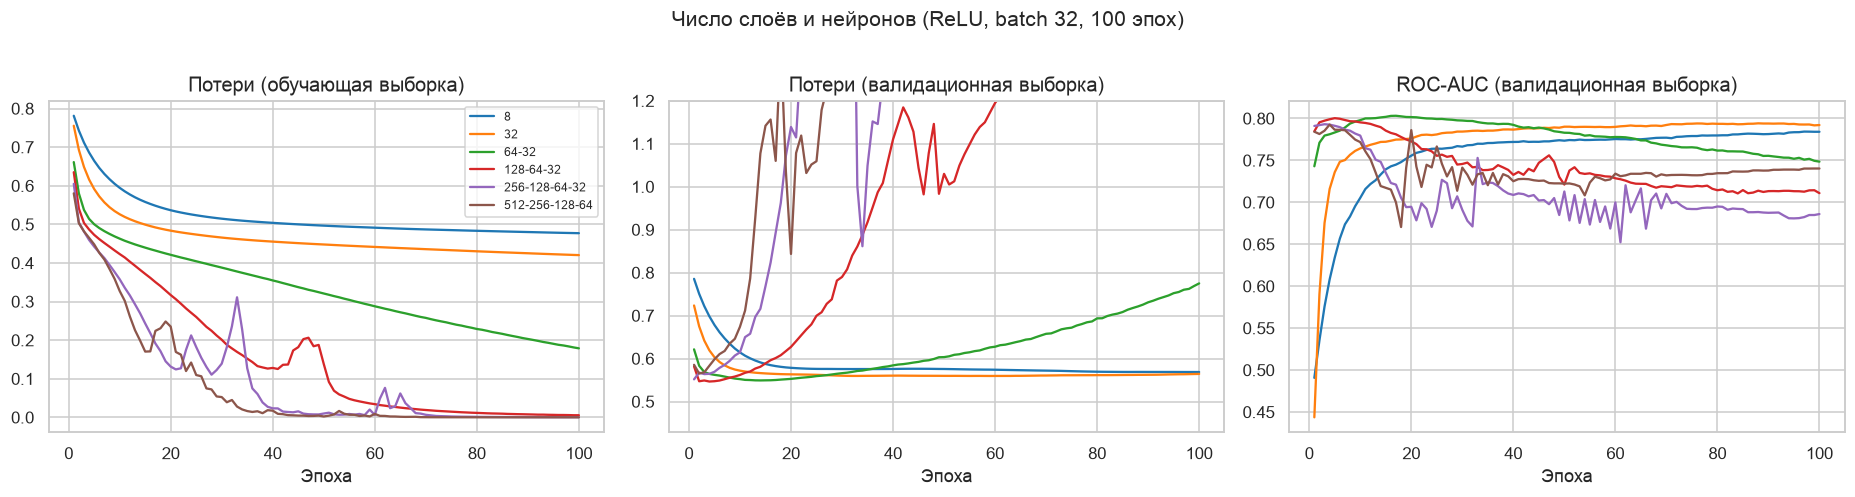

Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,Макс. val_AUC,val_loss (финал),val_accuracy,val_AUC,"Время, с"
8,100,105,100,0.568700,0.784300,0.568700,0.681000,0.784100,3.666500
32,100,417,59,0.559600,0.794200,0.564300,0.699400,0.792100,3.641500
64-32,100,2881,14,0.549200,0.803200,0.774900,0.681000,0.748500,4.126500
128-64-32,100,11905,4,0.546600,0.800300,1.822500,0.650300,0.710900,4.673900
256-128-64-32,100,46337,1,0.551700,0.793100,2.593500,0.650300,0.686000,5.362800
512-256-128-64,100,178689,2,0.565200,0.792700,2.913900,0.687100,0.740300,6.466800


In [23]:
architectures = {
    "8": (8,),
    "32": (32,),
    "64-32": (64, 32),
    "128-64-32": (128, 64, 32),
    "256-128-64-32": (256, 128, 64, 32),
    "512-256-128-64": (512, 256, 128, 64),
}
for name, hidden in architectures.items():
    run_experiment("3_layers", name, hidden=hidden, epochs=100, batch_size=32)
show_group("3_layers", title="Число слоёв и нейронов (ReLU, batch 32, 100 эпох)")

### Пояснение к исследованию числа слоёв и нейронов

Функция активации ReLU, размер батча 32, 100 эпох, без регуляризации.

| Архитектура | Число параметров | Мин. val_loss (эпоха) | val_loss после 100 эпох | Макс. ROC-AUC (валидация) |
|---|---|---|---|---|
| 8 | 105 | 0.569 (100) | 0.569 | 0.784 |
| 32 | 417 | 0.560 (59) | 0.564 | 0.794 |
| 64-32 | 2 881 | 0.549 (14) | 0.775 | 0.803 |
| 128-64-32 | 11 905 | 0.547 (4) | 1.823 | 0.800 |
| 256-128-64-32 | 46 337 | 0.552 (1) | 2.594 | 0.793 |
| 512-256-128-64 | 178 689 | 0.565 (2) | 2.914 | 0.793 |

- Сети с одним скрытым слоем (8 и 32 нейрона) обучаются медленно и почти не переобучаются: у сети из 8 нейронов `val_loss` продолжает снижаться до последней эпохи. Однако их минимальные потери выше, а ROC-AUC ниже: такие сети имеют недостаточную ёмкость.
- Сети с двумя-тремя скрытыми слоями (64-32 и 128-64-32) достигают наименьших потерь (0.547–0.549), но делают это за 4–14 эпох, после чего быстро переобучаются.
- Самые крупные сети (46 и 179 тыс. параметров) достигают минимума уже на 1–2 эпохе, а затем `val_loss` растёт до 2.6–2.9; их кривые на валидационной выборке сильно колеблются. Дальнейшее увеличение размера сети не улучшает минимальные потери – они даже растут.
- Минимальные потери всех шести архитектур различаются лишь на 0.022. Это означает, что качество ограничено информативностью признаков, а не ёмкостью модели: для 11 признаков и 651 объекта достаточно небольшой сети.

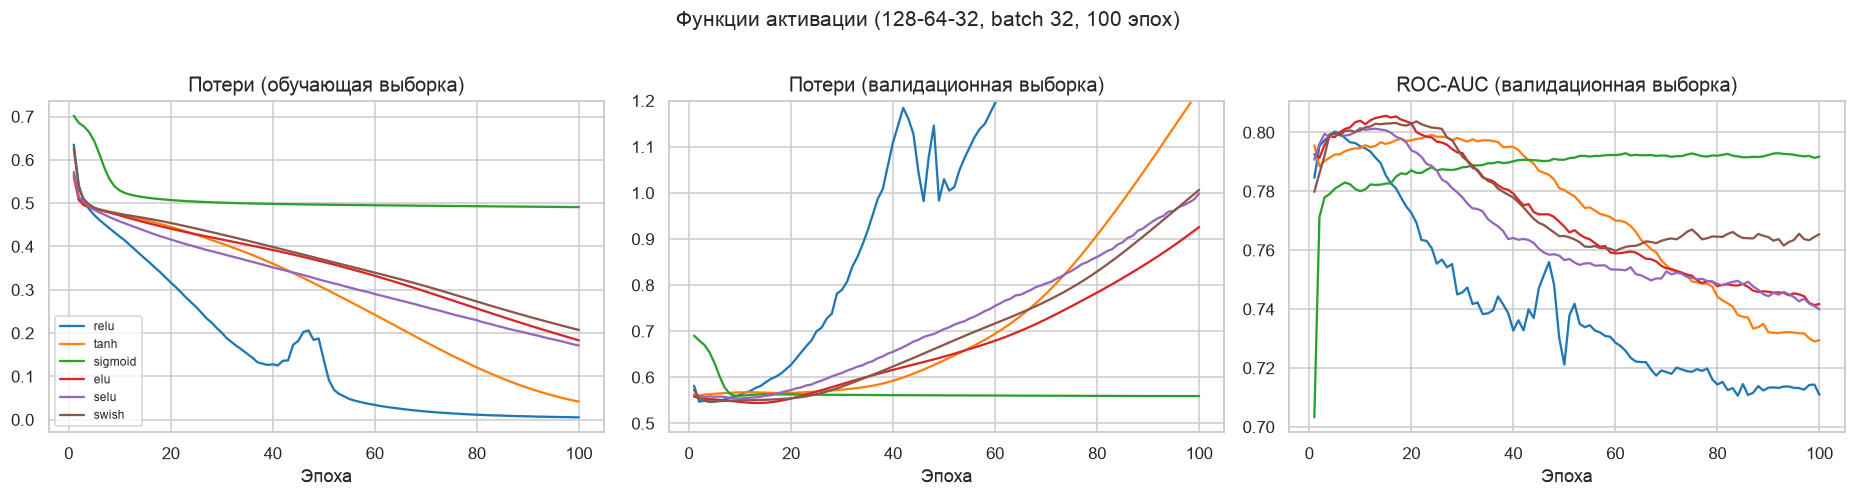

Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,Макс. val_AUC,val_loss (финал),val_accuracy,val_AUC,"Время, с"
relu,100,11905,4,0.546600,0.800300,1.822500,0.650300,0.710900,4.780000
tanh,100,11905,2,0.559800,0.799200,1.222600,0.662600,0.729500,4.695300
sigmoid,100,11905,100,0.559300,0.793000,0.559300,0.723900,0.791800,4.685400
elu,100,11905,14,0.544400,0.805700,0.926100,0.656400,0.741700,4.701800
selu,100,11905,10,0.553800,0.801500,0.998900,0.644200,0.739900,4.702500
swish,100,11905,4,0.547600,0.803800,1.006700,0.711700,0.765500,4.790500


In [24]:
for act in ["relu", "tanh", "sigmoid", "elu", "selu", "swish"]:
    run_experiment("4_activation", act, activation=act, hidden=(128, 64, 32), epochs=100, batch_size=32)
show_group("4_activation", title="Функции активации (128-64-32, batch 32, 100 эпох)")

### Пояснение к исследованию функций активации

Архитектура 128-64-32 (склонная к переобучению, что делает различия более заметными), размер батча 32, 100 эпох.

| Функция активации | Мин. val_loss (эпоха) | val_loss после 100 эпох | Макс. ROC-AUC (валидация) |
|---|---|---|---|
| ReLU, $\max(0, z)$ | 0.547 (4) | 1.823 | 0.800 |
| tanh | 0.560 (2) | 1.223 | 0.799 |
| sigmoid | 0.559 (100) | 0.559 | 0.793 |
| ELU | 0.544 (14) | 0.926 | 0.806 |
| SELU | 0.554 (10) | 0.999 | 0.802 |
| swish, $z\,\sigma(z)$ | 0.548 (4) | 1.007 | 0.804 |

- Сигмоида в скрытых слоях обучается значительно медленнее остальных функций: её производная не превышает 0.25, и в трёхслойной сети градиент затухает. За 100 эпох сеть не успевает переобучиться, `val_loss` монотонно снижается до последней эпохи (0.559), но остаётся выше, чем у других функций.
- ReLU, tanh и swish быстро достигают минимума (2–4 эпохи) и затем переобучаются. Сильнее всего переобучение выражено у ReLU (val_loss 1.82 к 100-й эпохе).
- ELU даёт наименьший минимальный `val_loss` (0.544) и наибольший ROC-AUC (0.806). Благодаря гладкой отрицательной части она не имеет «мёртвых» нейронов и обучается плавнее ReLU: минимум достигается на 14-й эпохе, а не на 4-й.
- Различия минимальных потерь между ReLU, ELU и swish (0.003) малы по сравнению с шумом валидационной выборки, поэтому функцию активации следует выбирать вместе с регуляризацией (см. следующий эксперимент).

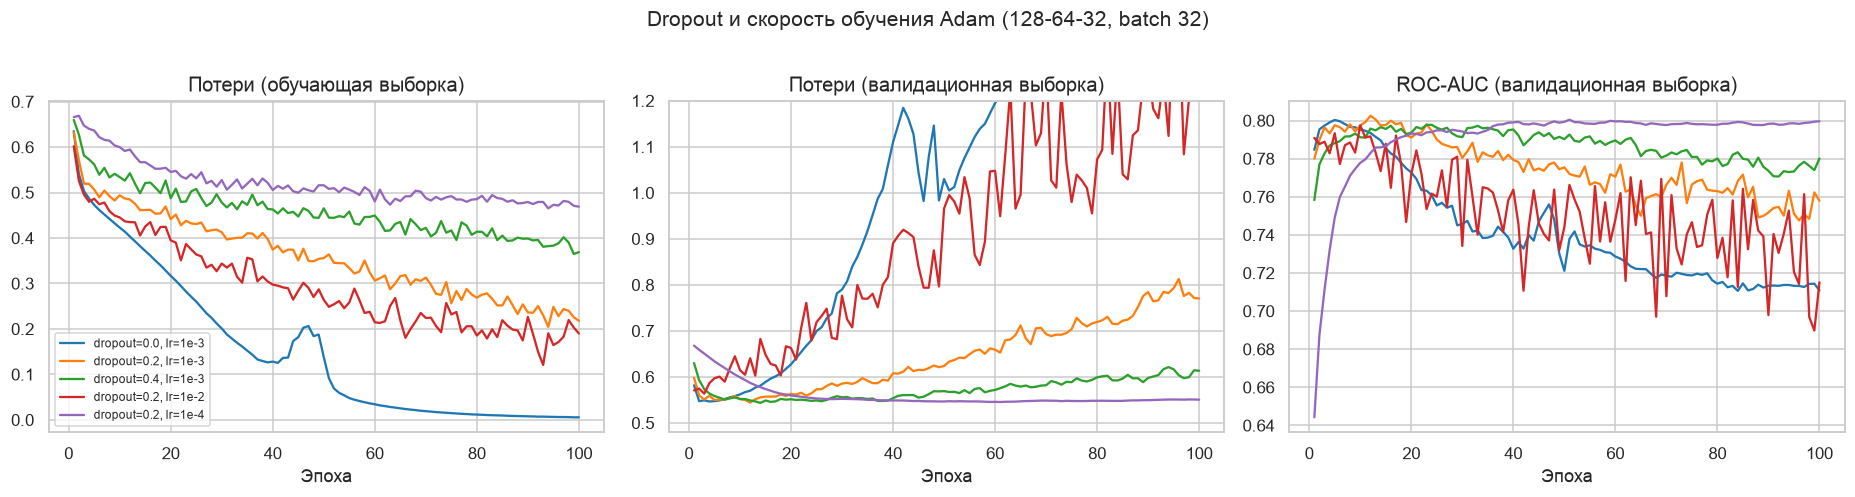

Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,Макс. val_AUC,val_loss (финал),val_accuracy,val_AUC,"Время, с"
"dropout=0.0, lr=1e-3",100,11905,4,0.546600,0.800300,1.822500,0.650300,0.710900,4.650900
"dropout=0.2, lr=1e-3",100,11905,12,0.544100,0.802500,0.770400,0.668700,0.757900,4.964700
"dropout=0.4, lr=1e-3",100,11905,14,0.543400,0.797700,0.613300,0.711700,0.780100,4.831900
"dropout=0.2, lr=1e-2",100,11905,3,0.563700,0.797400,1.207600,0.644200,0.715100,4.794600
"dropout=0.2, lr=1e-4",100,11905,61,0.545500,0.800500,0.550600,0.705500,0.799600,4.808200


In [25]:
for name, kw in {
    "dropout=0.0, lr=1e-3": dict(dropout=0.0, lr=1e-3),
    "dropout=0.2, lr=1e-3": dict(dropout=0.2, lr=1e-3),
    "dropout=0.4, lr=1e-3": dict(dropout=0.4, lr=1e-3),
    "dropout=0.2, lr=1e-2": dict(dropout=0.2, lr=1e-2),
    "dropout=0.2, lr=1e-4": dict(dropout=0.2, lr=1e-4),
}.items():
    run_experiment("5_regularization", name, hidden=(128, 64, 32), epochs=100, batch_size=32, **kw)
show_group("5_regularization", title="Dropout и скорость обучения Adam (128-64-32, batch 32)")

### Пояснение к исследованию прореживания и скорости обучения

Исследуется сеть 128-64-32 с функцией активации ReLU – наиболее склонная к переобучению конфигурация из предыдущих экспериментов.

| Вариант | Мин. val_loss (эпоха) | val_loss после 100 эпох | ROC-AUC после 100 эпох |
|---|---|---|---|
| dropout 0.0, lr $10^{-3}$ | 0.547 (4) | 1.823 | 0.711 |
| dropout 0.2, lr $10^{-3}$ | 0.544 (12) | 0.770 | 0.758 |
| dropout 0.4, lr $10^{-3}$ | **0.543** (14) | 0.613 | 0.780 |
| dropout 0.2, lr $10^{-2}$ | 0.564 (3) | 1.208 | 0.715 |
| dropout 0.2, lr $10^{-4}$ | 0.546 (61) | 0.551 | 0.800 |

- Прореживание (`Dropout`) – эффективный способ борьбы с переобучением: при доле 0.4 `val_loss` после 100 эпох равен 0.613 вместо 1.823 без прореживания, а ROC-AUC – 0.780 вместо 0.711. Минимум потерь при этом смещается с 4-й на 14-ю эпоху и становится немного ниже (0.543).
- Скорость обучения $10^{-2}$ слишком велика: минимум достигается уже на 3-й эпохе и оказывается наихудшим (0.564), а затем сеть быстро переобучается.
- Скорость $10^{-4}$ замедляет обучение примерно в 5 раз (минимум на 61-й эпохе), но позволяет получить почти такие же низкие потери (0.546) без переобучения к концу 100 эпох (ROC-AUC 0.800). Малая скорость обучения работает как неявная регуляризация, однако требует больше эпох.

Пять лучших запусков по минимальному val_loss (из всех экспериментов):


Эксперимент,Вариант,Эпох,Параметров,Лучшая эпоха (val_loss),Мин. val_loss,Макс. val_AUC,val_loss (финал),val_accuracy,val_AUC,"Время, с"
5_regularization,"dropout=0.4, lr=1e-3",100,11905,14,0.543400,0.797700,0.613300,0.711700,0.780100,4.831900
5_regularization,"dropout=0.2, lr=1e-3",100,11905,12,0.544100,0.802500,0.770400,0.668700,0.757900,4.964700
4_activation,elu,100,11905,14,0.544400,0.805700,0.926100,0.656400,0.741700,4.701800
5_regularization,"dropout=0.2, lr=1e-4",100,11905,61,0.545500,0.800500,0.550600,0.705500,0.799600,4.808200
5_regularization,"dropout=0.0, lr=1e-3",100,11905,4,0.546600,0.800300,1.822500,0.650300,0.710900,4.650900


Итоговая конфигурация: {'hidden': (128, 64, 32), 'activation': 'relu', 'dropout': 0.4, 'lr': 0.001, 'batch_size': 32}
Обучение остановлено на эпохе 44, восстановлены веса эпохи 14


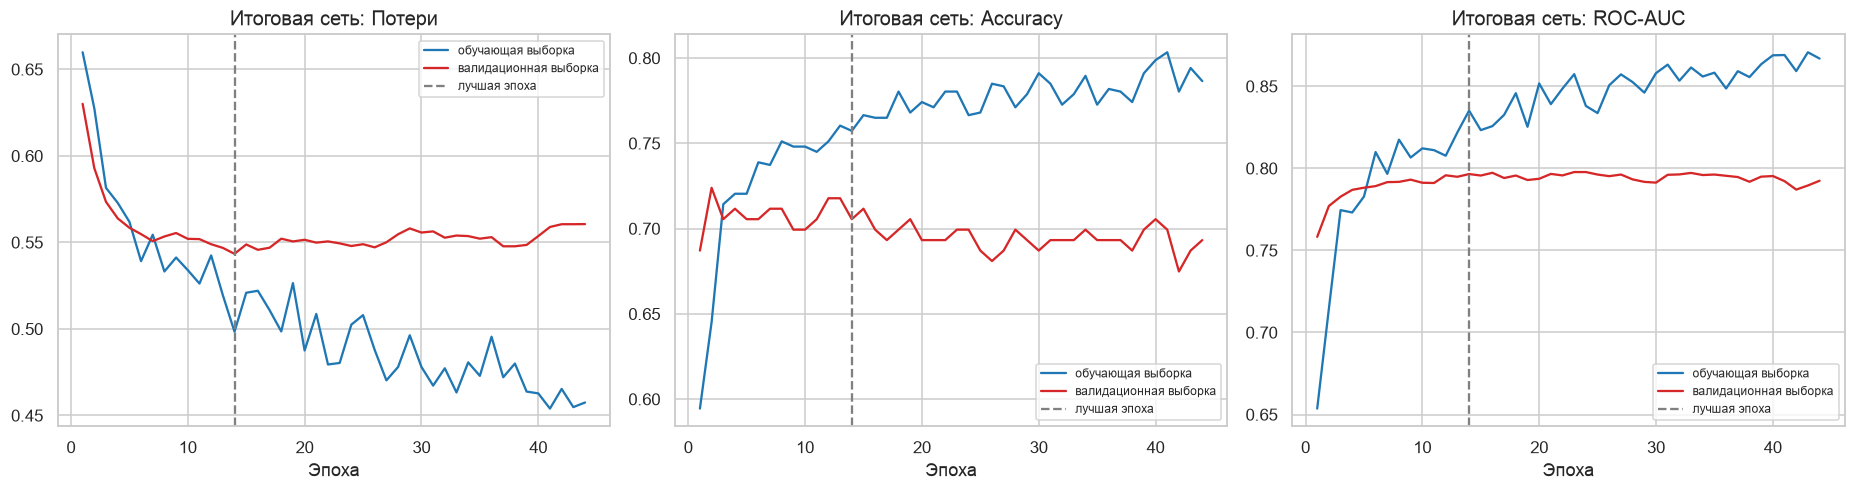

Метрики на тестовой выборке:


Модель,Accuracy,Precision,Recall,F1,ROC-AUC
"Базовая сеть 64-32, 300 эпох (переобученная)",0.691200,0.739600,0.651400,0.692700,0.750700
Нейронная сеть (TF),0.730400,0.793500,0.669700,0.726400,0.821100


In [26]:
runs_df = pd.DataFrame(nn_runs)
print("Пять лучших запусков по минимальному val_loss (из всех экспериментов):")
display(runs_df.sort_values("Мин. val_loss").head(5).drop(columns="config").round(4).style.hide(axis="index"))

# итоговая конфигурация = конфигурация лучшего запуска; число эпох выбирает EarlyStopping
FINAL = runs_df.sort_values("Мин. val_loss").iloc[0]["config"]
nn_final, hist_final = run_experiment("6_final", "final", epochs=500, early_stop=True, **FINAL)
print(f"Итоговая конфигурация: {FINAL}")
print(f"Обучение остановлено на эпохе {len(hist_final)}, восстановлены веса эпохи "
      f"{int(hist_final['val_loss'].idxmin())}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (tr_key, va_key, title) in zip(axes, [("loss", "val_loss", "Потери"),
                                             ("accuracy", "val_accuracy", "Accuracy"),
                                             ("auc", "val_auc", "ROC-AUC")]):
    ax.plot(hist_final.index, hist_final[tr_key], label="обучающая выборка", color="#1f77b4")
    ax.plot(hist_final.index, hist_final[va_key], label="валидационная выборка", color="#d62728")
    ax.axvline(int(hist_final["val_loss"].idxmin()), color="gray", linestyle="--", label="лучшая эпоха")
    ax.set_title(f"Итоговая сеть: {title}")
    ax.set_xlabel("Эпоха")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


class KerasWrapper:
    """Обёртка, чтобы сеть оценивалась той же функцией evaluate, что и sklearn-модели."""
    def __init__(self, m):
        self.m = m

    def predict_proba(self, X_):
        p = self.m.predict(np.asarray(X_, dtype="float32"), verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X_):
        return (self.predict_proba(X_)[:, 1] >= 0.5).astype(int)


nn_wrapped = KerasWrapper(nn_final)
nn_metrics = evaluate(nn_wrapped, X_te_nn, "Нейронная сеть (TF)")
base_wrapped = KerasWrapper(model_long)
print("Метрики на тестовой выборке:")
display(pd.DataFrame([evaluate(base_wrapped, X_te_nn, "Базовая сеть 64-32, 300 эпох (переобученная)"),
                      nn_metrics]).round(4).style.hide(axis="index"))

### Пояснение к итоговой нейронной сети

Выбор конфигурации выполняется автоматически: из 24 экспериментальных запусков выбирается запуск с наименьшим значением `val_loss`. Им оказалась сеть 128-64-32 с функцией активации ReLU, долей прореживания 0.4, оптимизатором Adam (скорость обучения $10^{-3}$) и размером батча 32 (минимальный `val_loss` 0.543). Пять лучших запусков различаются по этому показателю не более чем на 0.003. Число эпох определяется ранней остановкой `EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)`: обучение прекращено на 44-й эпохе, восстановлены веса 14-й эпохи, на которой достигнут минимум `val_loss`.

Итоговая архитектура:

`Input(11) → Dense(128, ReLU) → Dropout(0.4) → Dense(64, ReLU) → Dropout(0.4) → Dense(32, ReLU) → Dropout(0.4) → Dense(1, sigmoid)`, 11 905 параметров.

Кривые обучения итоговой сети: в первые эпохи потери на обучающей выборке выше, чем на валидационной, так как прореживание действует только при обучении. После 14-й эпохи потери на обучающей выборке продолжают снижаться, а на валидационной выходят на плато около 0.55, и ROC-AUC на валидации стабилизируется на уровне 0.79–0.80. Ранняя остановка возвращает модель к моменту, когда переобучение ещё не началось.

Результаты на тестовой выборке:

| Сеть | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Базовая 64-32, 300 эпох (переобученная) | 0.691 | 0.740 | 0.651 | 0.693 | 0.751 |
| Итоговая (прореживание и ранняя остановка) | 0.730 | 0.794 | 0.670 | 0.726 | 0.821 |

Регуляризация и ранняя остановка повысили ROC-AUC на тестовой выборке на 0.070, а Accuracy – почти на 4 процентных пункта. Итоговая сеть, как и большинство моделей, осторожно относит вина к классу «хорошее» (Precision 0.794 выше Recall 0.670).

In [27]:
import sys
os.environ["PATH"] = os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"]
%load_ext tensorboard
%tensorboard --logdir logs/fit --port 6006

Приведённая выше команда запускает TensorBoard непосредственно в ноутбуке: в Jupyter и VS Code отображается встроенная панель. Вне ноутбука тот же интерфейс запускается из терминала командой

```bash
.venv/bin/tensorboard --logdir logs/fit --port 6006
```

после чего доступен в браузере по адресу http://localhost:6006. На вкладке Scalars отображаются кривые `epoch_loss`, `epoch_accuracy` и `epoch_auc` для обучающей и валидационной выборок, на вкладках Histograms и Distributions – изменение распределений весов слоёв по эпохам. Фильтр запусков в левой панели позволяет сравнивать варианты одного эксперимента (например, все запуски `3_layers/*`).

Ниже те же скалярные метрики прочитаны непосредственно из файлов событий TensorBoard, что позволяет сохранить графики в отчёте.

Структура логов TensorBoard:
  logs/fit/1_epochs/: 300 эпох
  logs/fit/2_batch/: batch=128, batch=16, batch=256, batch=32, batch=64, batch=8
  logs/fit/3_layers/: 128-64-32, 256-128-64-32, 32, 512-256-128-64, 64-32, 8
  logs/fit/4_activation/: elu, relu, selu, sigmoid, swish, tanh
  logs/fit/5_regularization/: dropout=0.0, lr=1e-3, dropout=0.2, lr=1e-2, dropout=0.2, lr=1e-3, dropout=0.2, lr=1e-4, dropout=0.4, lr=1e-3
  logs/fit/6_final/: final


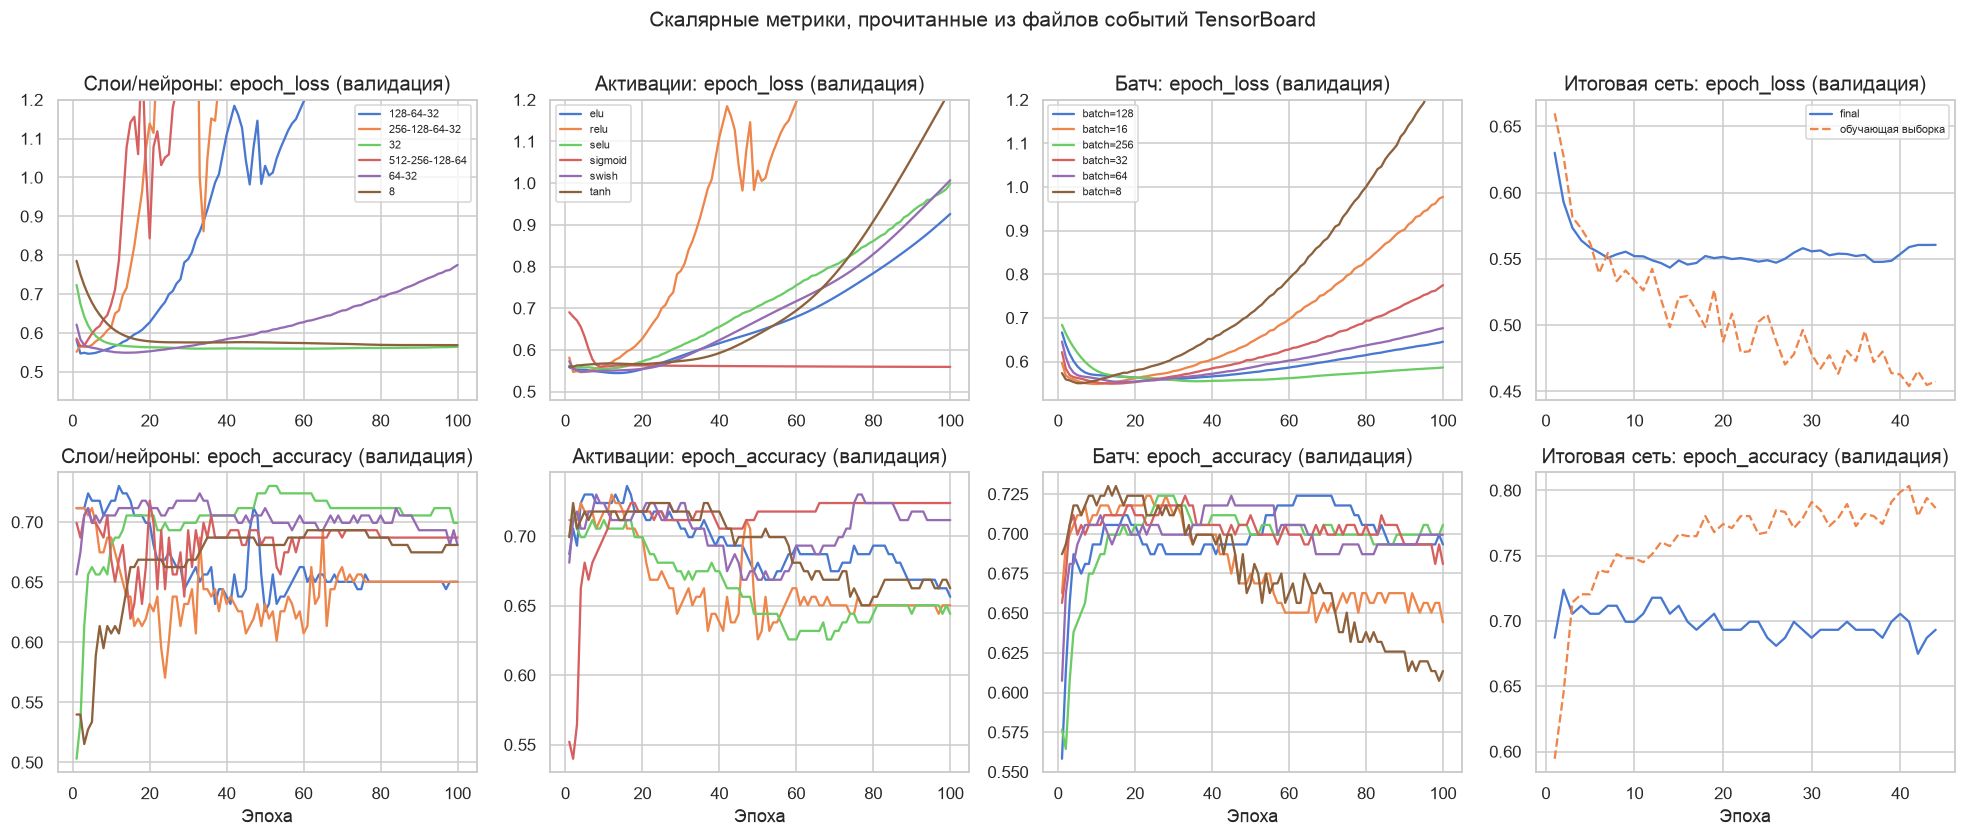

In [28]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator


def read_tb_scalars(run_dir):
    """Читает скаляры из event-файлов TensorBoard (папки train/ и validation/)."""
    out = {}
    for split in ["train", "validation"]:
        ea = EventAccumulator(os.path.join(run_dir, split), size_guidance={"tensors": 0})
        ea.Reload()
        for tag in ea.Tags()["tensors"]:
            if tag.startswith("epoch_"):
                vals = [(e.step + 1, float(tf.make_ndarray(e.tensor_proto))) for e in ea.Tensors(tag)]
                out[(split, tag)] = pd.Series(dict(vals))
    return out


groups = sorted(d for d in os.listdir(LOG_ROOT) if not d.startswith("."))
print("Структура логов TensorBoard:")
for g in groups:
    print(f"  {LOG_ROOT}/{g}/: " + ", ".join(sorted(os.listdir(f"{LOG_ROOT}/{g}"))))

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for col, (g, title) in enumerate([("3_layers", "Слои/нейроны"), ("4_activation", "Активации"),
                                  ("2_batch", "Батч"), ("6_final", "Итоговая сеть")]):
    for run in sorted(os.listdir(f"{LOG_ROOT}/{g}")):
        sc = read_tb_scalars(f"{LOG_ROOT}/{g}/{run}")
        axes[0, col].plot(sc[("validation", "epoch_loss")], label=run)
        axes[1, col].plot(sc[("validation", "epoch_accuracy")], label=run)
        if g == "6_final":
            axes[0, col].plot(sc[("train", "epoch_loss")], "--", label="обучающая выборка")
            axes[1, col].plot(sc[("train", "epoch_accuracy")], "--", label="обучающая выборка")
    axes[0, col].set_title(f"{title}: epoch_loss (валидация)")
    axes[0, col].set_ylim(top=min(axes[0, col].get_ylim()[1], 1.2))
    axes[1, col].set_title(f"{title}: epoch_accuracy (валидация)")
    axes[1, col].set_xlabel("Эпоха")
    axes[0, col].legend(fontsize=7)
plt.suptitle("Скалярные метрики, прочитанные из файлов событий TensorBoard", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

### Пояснение к логам TensorBoard

Логи организованы по экспериментам: `logs/fit/<эксперимент>/<вариант>/{train, validation}`. Такая структура позволяет в интерфейсе TensorBoard отфильтровать один эксперимент и сравнить его варианты на одном графике. Всего записано 25 запусков в шести группах: `1_epochs` (1), `2_batch` (6), `3_layers` (6), `4_activation` (6), `5_regularization` (5) и `6_final` (1).

Графики, построенные по файлам событий, совпадают с историями `model.fit`:

- В группе `3_layers` потери на валидационной выборке у сетей с 3–4 скрытыми слоями после нескольких эпох резко возрастают, а у сетей с одним слоем (8 и 32 нейрона) остаются низкими и стабильными.
- В группе `4_activation` выделяется сигмоида: её `val_loss` плавно снижается на протяжении всех 100 эпох, тогда как у остальных функций он растёт после 2–14 эпох.
- В группе `2_batch` скорость переобучения монотонно зависит от размера батча: быстрее всего `val_loss` растёт при батче 8, медленнее всего – при батче 256.
- У итоговой сети (`6_final`) потери на обучающей выборке продолжают снижаться, а на валидационной остаются на уровне около 0.55; обучение остановлено на 44-й эпохе.

### Снимки интерфейса TensorBoard

Снимки получены при запущенной команде `tensorboard --logdir logs/fit` (вкладка Time Series, коэффициент сглаживания 0.6).

Эксперимент с числом слоёв и нейронов (фильтр запусков `3_layers`, метрика `epoch_loss`). Для крупных сетей хорошо заметно расхождение кривых для обучающей и валидационной выборок:

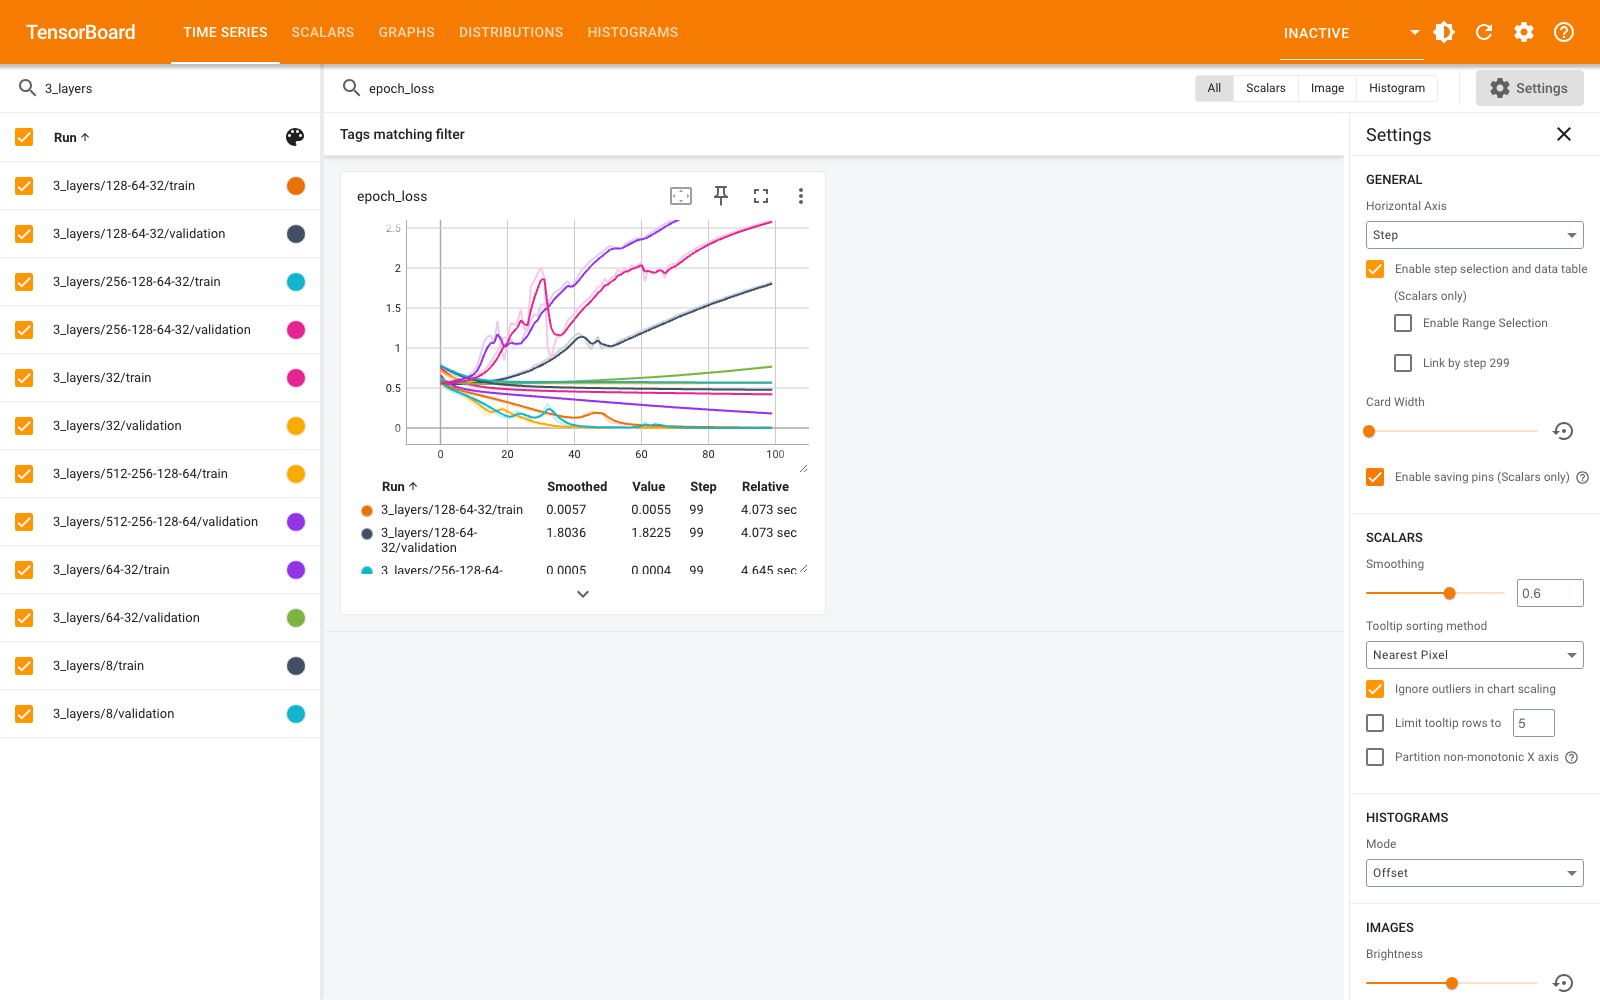

Итоговая сеть (фильтр `6_final`): метрики `epoch_accuracy`, `epoch_auc`, `epoch_learning_rate` и `epoch_loss` для обучающей и валидационной выборок. На последнем шаге (43, то есть 44-я эпоха) ROC-AUC равен 0.867 на обучающей выборке и 0.792 на валидационной, функция потерь – 0.458 и 0.561 соответственно; скорость обучения постоянна и равна $10^{-3}$:

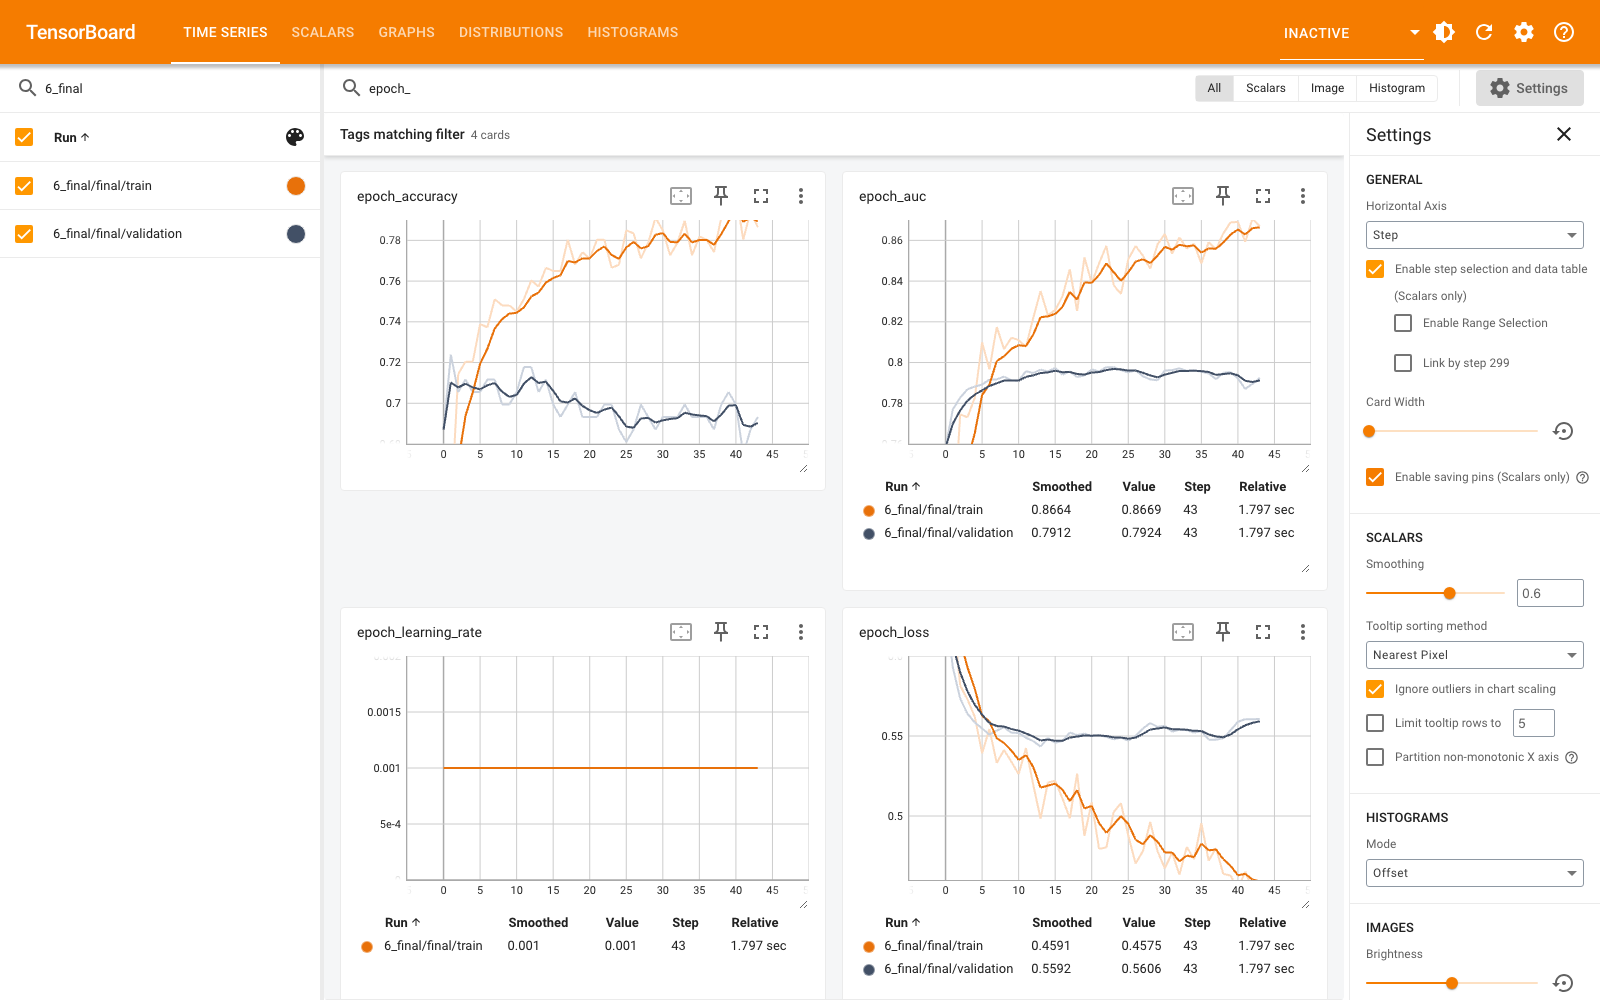

Функции активации (фильтр `4_activation`, метрика `epoch_auc`):

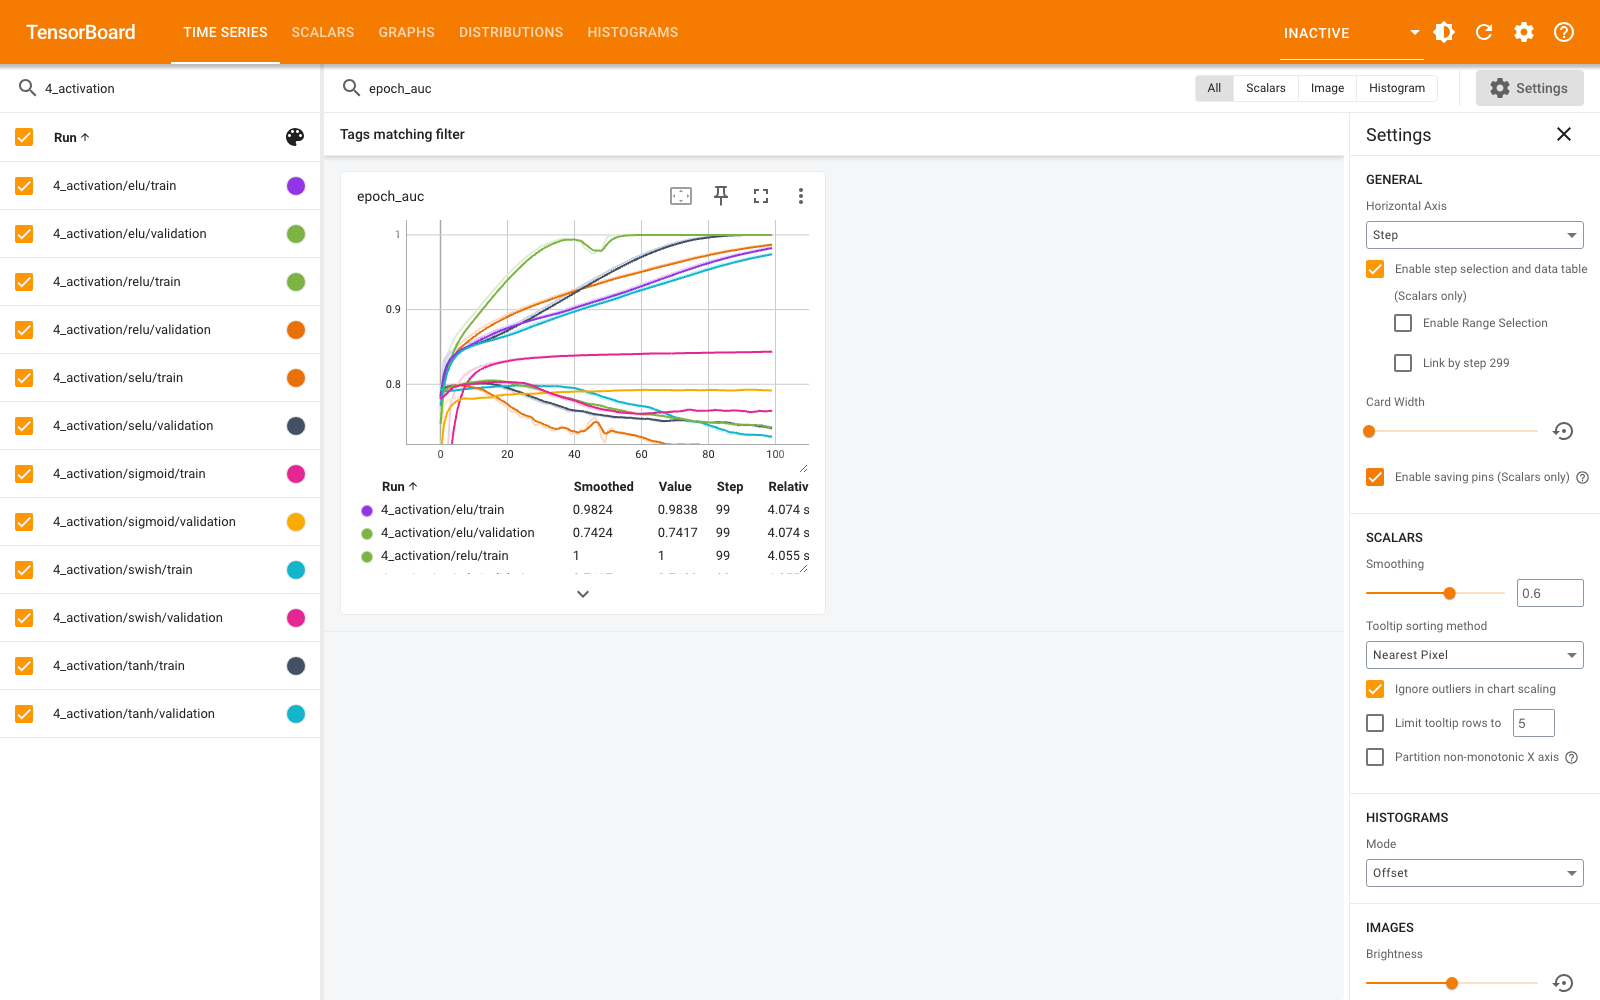

Гистограммы весов (`kernel`) четырёх слоёв `Dense` итоговой сети по эпохам (`histogram_freq=1`). Распределения весов первых трёх слоёв сохраняют форму, близкую к равномерной начальной инициализации Глоро, и лишь немного расширяются; веса выходного слоя (32 значения) изменяются заметнее. Отсутствие неограниченного роста или затухания весов говорит о том, что обучение протекает устойчиво, а прореживание и ранняя остановка не дают весам «разрастись» под обучающую выборку:

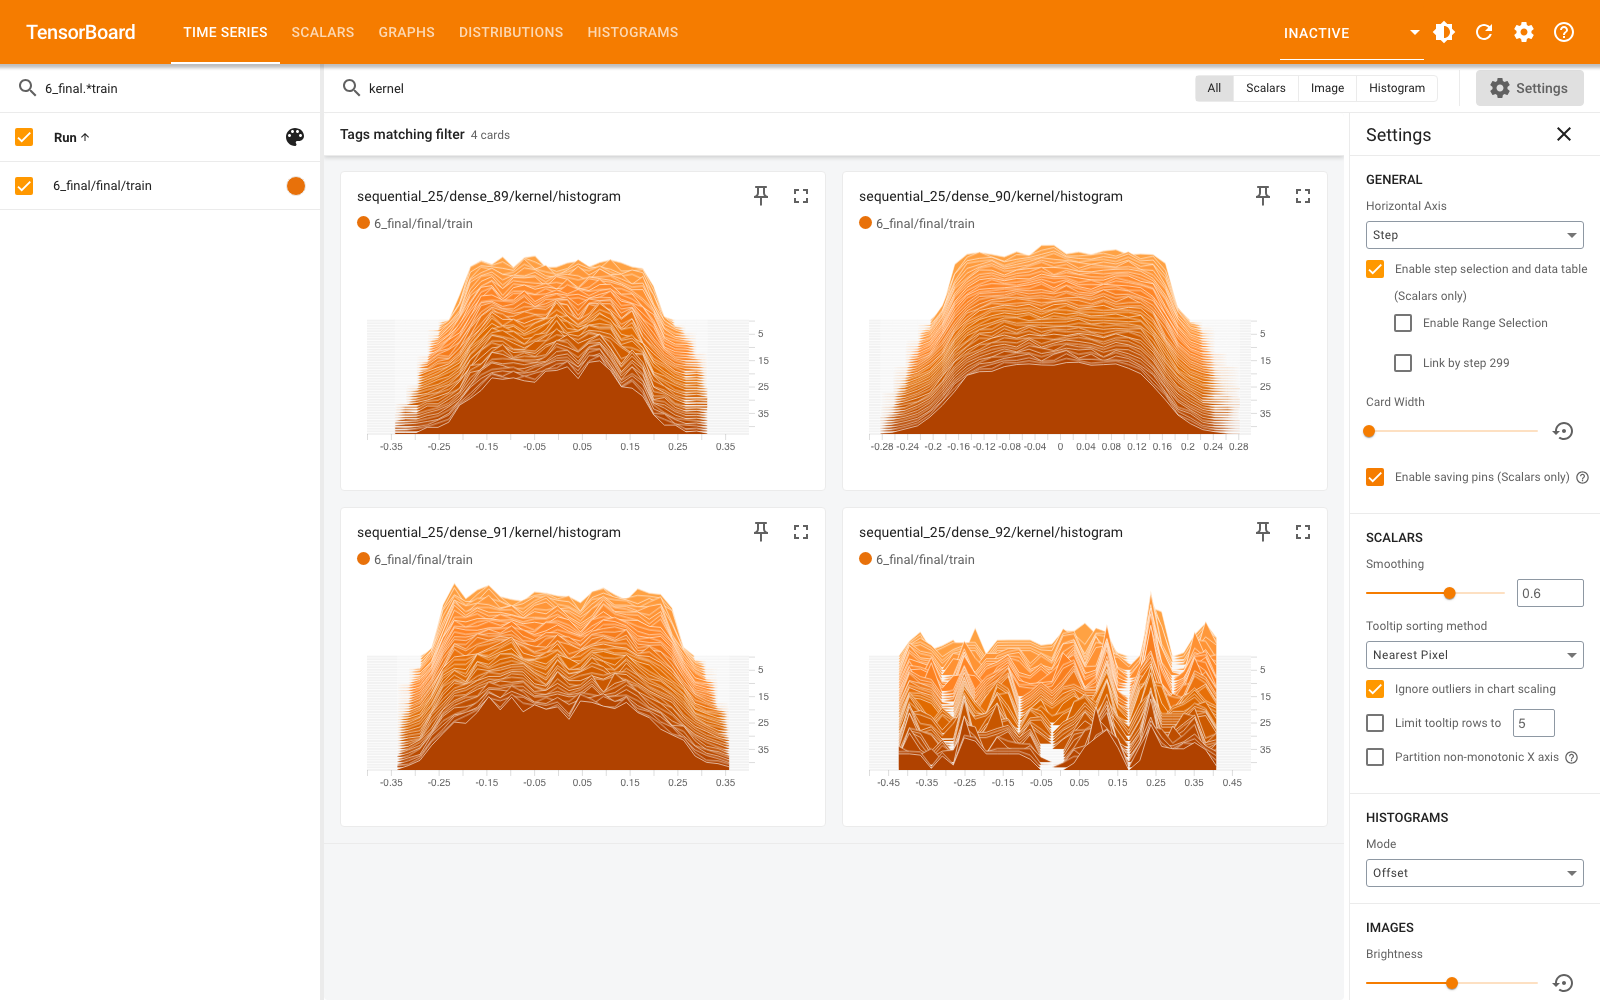

## 7. Сравнительный анализ

ИТОГОВОЕ СРАВНЕНИЕ НА ТЕСТОВОЙ ВЫБОРКЕ (настроенные модели)


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Наивный Байес,0.705900,0.676300,0.862400,0.758100,0.806000
Дерево решений,0.740200,0.769200,0.733900,0.751200,0.805600
LDA,0.730400,0.793500,0.669700,0.726400,0.818800
SVM,0.750000,0.808500,0.697200,0.748800,0.828700
kNN,0.725500,0.767700,0.697200,0.730800,0.810900
Нейронная сеть (TF),0.730400,0.793500,0.669700,0.726400,0.821100


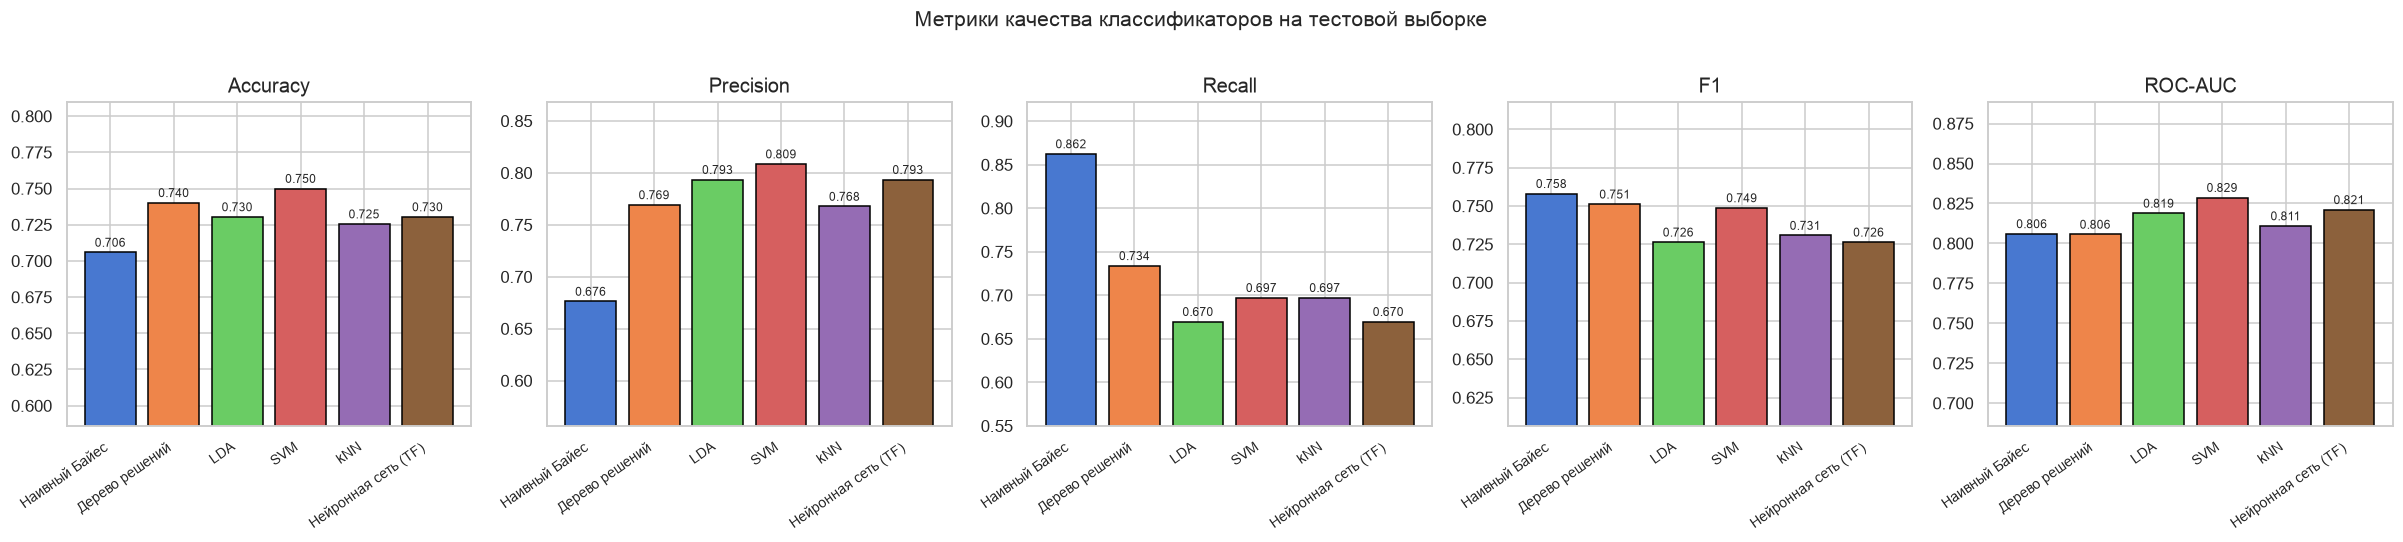

In [29]:
final_df = pd.DataFrame(results_tuned + [nn_metrics]).set_index("Модель")
print("ИТОГОВОЕ СРАВНЕНИЕ НА ТЕСТОВОЙ ВЫБОРКЕ (настроенные модели)")
display(final_df.round(4).style.highlight_max(axis=0, color="#c7e9c0"))

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.8))
palette = sns.color_palette("muted", len(final_df))
for ax, m in zip(axes, metrics):
    bars = ax.bar(range(len(final_df)), final_df[m], color=palette, edgecolor="black")
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
    ax.set_xticks(range(len(final_df)))
    ax.set_xticklabels(final_df.index, rotation=35, ha="right", fontsize=9)
    ax.set_ylim(max(0, final_df[m].min() - 0.12), min(1.0, final_df[m].max() + 0.06))
    ax.set_title(m)
plt.suptitle("Метрики качества классификаторов на тестовой выборке", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### Пояснение к сравнительной таблице

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Наивный байесовский классификатор (GaussianNB) | 0.706 | 0.676 | **0.862** | **0.758** | 0.806 |
| Дерево решений | 0.740 | 0.769 | 0.734 | 0.751 | 0.806 |
| LDA | 0.730 | 0.794 | 0.670 | 0.726 | 0.819 |
| SVM (RBF) | **0.750** | **0.809** | 0.697 | 0.749 | **0.829** |
| kNN | 0.725 | 0.768 | 0.697 | 0.731 | 0.811 |
| Нейронная сеть (TF) | 0.730 | 0.794 | 0.670 | 0.726 | 0.821 |

- SVM с RBF-ядром лидирует по трём метрикам из пяти: Accuracy (0.750), Precision (0.809) и ROC-AUC (0.829).
- Наибольшие Recall (0.862) и F1 (0.758) у наивного байесовского классификатора, однако это следствие сдвига порога, а не лучшего разделения классов: модель относит к хорошим винам 139 из 204 образцов и платит за это самой низкой Precision (0.676) и Accuracy (0.706). Метрика F1 при положительном классе, составляющем больше половины выборки, поощряет такую стратегию.
- Дерево решений обладает наиболее сбалансированными Precision и Recall (0.769 и 0.734) и вторым по величине F1 (0.751), но его ROC-AUC (0.806) минимален: дерево выдаёт ступенчатые оценки (32 листа), которые хуже ранжируют объекты.
- LDA и нейронная сеть получили одинаковые Accuracy, Precision, Recall и F1 – их матрицы ошибок на тестовой выборке совпали, а ROC-AUC различается незначительно (0.819 и 0.821). Нелинейная нейронная сеть не превзошла линейную модель, что подтверждает близость границы классов к линейной.
- Разброс ROC-AUC между всеми шестью моделями составляет лишь 0.023, а Accuracy – 0.044 (9 образцов тестовой выборки).

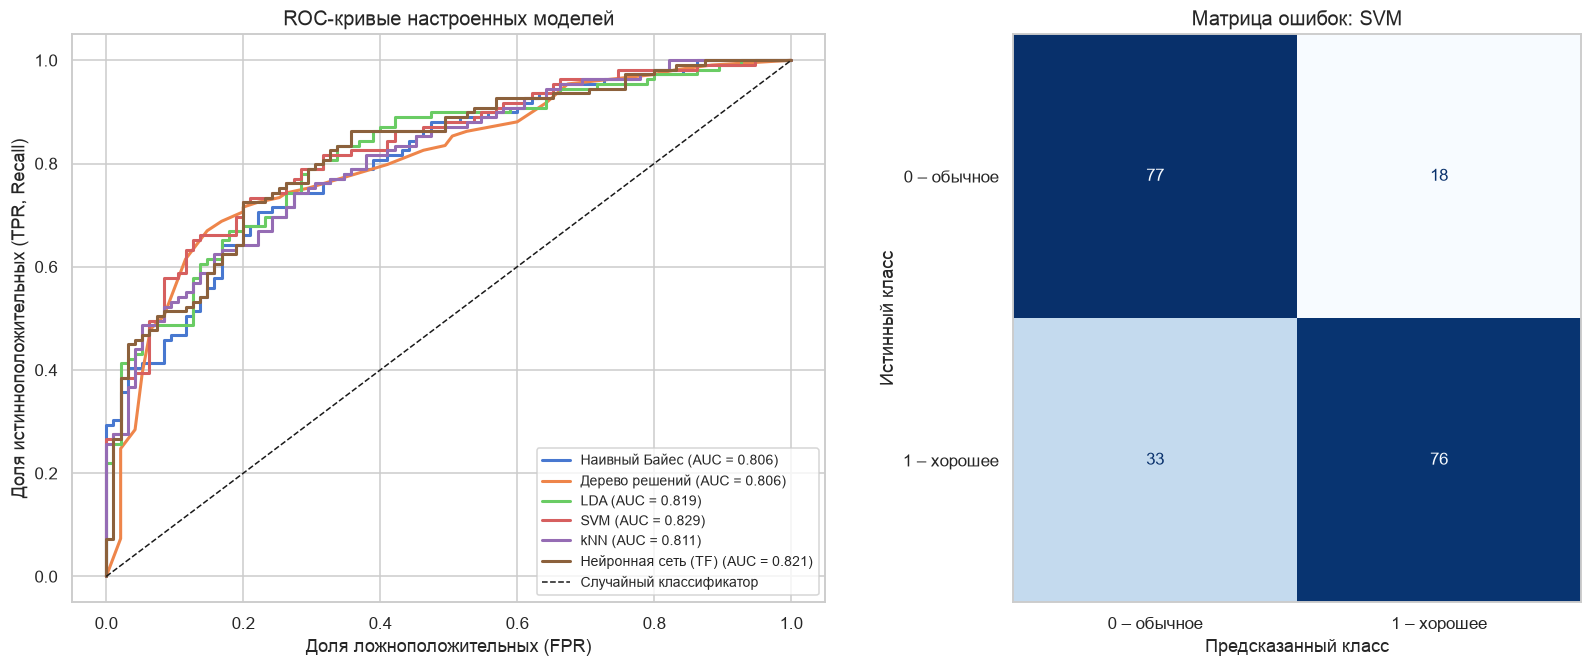

Средний ранг модели по пяти метрикам (1 – лучший):


,Средний ранг
Модель,
SVM,1.9
Дерево решений,3.2
Наивный Байес,3.8
Нейронная сеть (TF),3.8
LDA,4.0
kNN,4.3


Бутстреп-оценка ROC-AUC на тестовой выборке (1000 повторов):


,ROC-AUC (среднее),95% ДИ: нижняя,95% ДИ: верхняя
Наивный Байес,0.808,0.746,0.865
Дерево решений,0.806,0.746,0.862
LDA,0.820,0.761,0.877
SVM,0.829,0.771,0.883
kNN,0.812,0.751,0.867
Нейронная сеть (TF),0.822,0.766,0.877


In [30]:
all_for_roc = dict(tuned_models)
all_for_roc["Нейронная сеть (TF)"] = (nn_wrapped, X_te_nn)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.15, 1]})
for (name, (model, Xte)), c in zip(all_for_roc.items(), palette):
    s = get_scores(model, Xte)
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=c, linewidth=2, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Случайный классификатор")
axes[0].set_xlabel("Доля ложноположительных (FPR)")
axes[0].set_ylabel("Доля истинноположительных (TPR, Recall)")
axes[0].set_title("ROC-кривые настроенных моделей")
axes[0].legend(fontsize=9, loc="lower right")

best_name = final_df["ROC-AUC"].idxmax()
best_model, best_X = all_for_roc[best_name]
cm = confusion_matrix(y_test, best_model.predict(best_X))
ConfusionMatrixDisplay(cm, display_labels=["0 – обычное", "1 – хорошее"]).plot(ax=axes[1], cmap="Blues",
                                                                              colorbar=False, values_format="d")
axes[1].set_title(f"Матрица ошибок: {best_name}")
axes[1].set_xlabel("Предсказанный класс")
axes[1].set_ylabel("Истинный класс")
axes[1].grid(False)
plt.tight_layout()
plt.show()

rank = final_df.rank(ascending=False).mean(axis=1).sort_values()
print("Средний ранг модели по пяти метрикам (1 – лучший):")
display(rank.round(2).rename("Средний ранг").to_frame())

# Устойчивость сравнения: тестовая выборка мала, поэтому оценим разброс ROC-AUC бутстрепом
rng = np.random.default_rng(SEED)
scores = {n: get_scores(m, Xte) for n, (m, Xte) in all_for_roc.items()}
yt = y_test.values
boot = {n: [] for n in scores}
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() == yt[idx].max():
        continue
    for n, s in scores.items():
        boot[n].append(roc_auc_score(yt[idx], s[idx]))
boot_df = pd.DataFrame({n: [np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)] for n, v in boot.items()},
                       index=["ROC-AUC (среднее)", "95% ДИ: нижняя", "95% ДИ: верхняя"]).T
print("Бутстреп-оценка ROC-AUC на тестовой выборке (1000 повторов):")
display(boot_df.round(3))

### Пояснение к ROC-кривым и выбору модели

ROC-кривые всех моделей расположены близко друг к другу и пересекаются; ступенчатая форма кривых объясняется малым объёмом тестовой выборки (95 обычных и 109 хороших вин). Кривая дерева решений имеет наименьшее число ступеней, поскольку дерево выдаёт ограниченный набор значений вероятности. В области малых FPR (до 0.1) лучше остальных модели, выдающие непрерывные оценки: при 10% ложноположительных они находят около половины хороших вин.

Матрица ошибок лучшей модели (SVM): из 95 обычных вин правильно распознано 77, ошибочно отнесено к хорошим 18; из 109 хороших вин правильно распознано 76, пропущено 33. Пропусков хороших вин почти вдвое больше, чем ложных срабатываний: модель «осторожна» и относит вино к хорошим только при достаточно высоком содержании алкоголя и низкой летучей кислотности. При необходимости соотношение Precision и Recall можно изменить, сдвинув порог решающей функции; ROC-AUC от этого не зависит.

Средний ранг по пяти метрикам: SVM – 1.9 (лучший), дерево решений – 3.2, наивный Байес и нейронная сеть – 3.8, LDA – 4.0, kNN – 4.3.

Бутстреп-оценка (1000 повторных выборок из тестового набора) показывает, что 95% доверительные интервалы ROC-AUC имеют ширину около 0.11 и сильно перекрываются: например, у SVM [0.771; 0.883], у наивного Байеса [0.746; 0.865]. Следовательно, по одной тестовой выборке из 204 образцов различия между моделями статистически не значимы. Поэтому при выборе модели учитывается и более устойчивая оценка – ROC-AUC пятикратной кросс-валидации на обучающей выборке, по которой порядок моделей тот же: SVM (0.828), LDA (0.826), kNN (0.823), наивный Байес (0.803), дерево решений (0.786).

**Вывод.** Лучшим подходом для данного набора данных является метод опорных векторов с RBF-ядром ($C = 3$, $\gamma = 0.02$): он лидирует и при кросс-валидации, и на тестовой выборке по ROC-AUC, Accuracy и Precision. Малое значение $\gamma$ означает гладкую, почти линейную границу, поэтому близкие результаты показывают линейные LDA (0.819) и нейронная сеть (0.821). Если важна интерпретируемость, разумной альтернативой является LDA: она уступает SVM всего 0.002 при кросс-валидации, обучается мгновенно и даёт наглядные веса признаков. Нейронная сеть для 11 признаков и 814 объектов преимуществ не даёт и требует регуляризации, а дерево решений уступает остальным методам по качеству ранжирования.

## 8. Заключение

1. Для исследования методов классификации выбран набор данных Wine Quality (красные вина «Vinho Verde»): 1 143 образца, 11 физико-химических признаков и экспертная оценка качества от 3 до 8. Задача сведена к бинарной классификации «хорошее вино» (оценка ≥ 6, 54.3%) / «обычное вино» (оценка ≤ 5, 45.7%); классы близки к сбалансированным.
2. Разведочный анализ показал, что качество вина сильнее всего связано с содержанием алкоголя (корреляция Спирмена +0.46; среди вин крепче 11.5% хороших более 90%), сульфатами (+0.36) и летучей кислотностью (−0.34). Распределения классов по всем признакам существенно перекрываются.
3. Предобработка: удалено 125 дубликатов, выбросы ограничены 1-м и 99-м перцентилями, шесть асимметричных признаков логарифмированы, все признаки стандартизованы. Параметры преобразований вычислены только по обучающей выборке. Данные разделены в соотношении 80/20 со стратификацией (814 и 204 образца), все эксперименты воспроизводимы (`SEED = 42`).
4. Гиперпараметры подбирались пятикратной стратифицированной кросс-валидацией по критерию ROC-AUC. Наибольший эффект настройка дала для дерева решений (+0.150 по ROC-AUC на тестовой выборке за счёт ограничения глубины до 6 и не менее 15 объектов в листе), заметный – для SVM (+0.017; $C = 3$, $\gamma = 0.02$), наивного Байеса (+0.015) и kNN (+0.011; $k = 75$, взвешивание по расстоянию, манхэттенская метрика). Для LDA настройка практически не нужна. Во всех случаях оптимум соответствует более простой и гладкой модели, чем модель по умолчанию.
5. Нейронная сеть на TensorFlow: исследовано влияние числа эпох (минимум `val_loss` на 14-й эпохе, полное запоминание обучающей выборки к 200-й), размера батча, архитектуры (от 105 до 179 тыс. параметров), шести функций активации, прореживания и скорости обучения; все 25 запусков записаны в логи TensorBoard. Установлено, что увеличение сети не улучшает качество, а решающими являются регуляризация и ранняя остановка. Итоговая сеть 128-64-32 с ReLU и Dropout 0.4 достигла ROC-AUC 0.821 против 0.751 у переобученной базовой сети.
6. По результатам сравнения наилучшей моделью признан SVM с RBF-ядром (Accuracy 0.750, Precision 0.809, Recall 0.697, F1 0.749, ROC-AUC 0.829; ROC-AUC при кросс-валидации 0.828). Близкие результаты показали LDA и нейронная сеть, что указывает на почти линейную границу между классами. Разброс ROC-AUC между моделями (0.023) меньше ширины доверительного интервала, то есть качество ограничено информативностью физико-химических признаков и субъективностью экспертной оценки на границе 5/6 баллов, а не выбором метода.

## Список источников

1. Scikit-learn: Supervised learning [Электронный ресурс]. – URL: https://scikit-learn.org/stable/supervised_learning.html
2. TensorFlow: Keras API [Электронный ресурс]. – URL: https://www.tensorflow.org/api_docs/python/tf/keras
3. TensorBoard: Get started [Электронный ресурс]. – URL: https://www.tensorflow.org/tensorboard/get_started
4. Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning. – 2nd ed. – Springer, 2009.
5. Goodfellow I., Bengio Y., Courville A. Deep Learning. – MIT Press, 2016.
6. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties // Decision Support Systems. – 2009. – Vol. 47, № 4. – P. 547–553.
7. Wine Quality Dataset [Электронный ресурс] // Kaggle. – URL: https://www.kaggle.com/datasets/yasserh/wine-quality-dataset